# DRM · Lab 04 — Assignment 03 Sheet (GRADED)
## Option Pricing and Synthetic Portfolios on **your allotted Nifty 50 stock**

**Course:** DRM (<ECON F354>) · <Semester 1 - 2026-27>
**Instructor:** <Prof. Aditya Sharma> · BITS Pilani
**Total marks:** 45 **Deadline:** `<DD Mon 2026, Midnight>`

---

### What this assignment is

You have to choose one company from the **Nifty 50**. On that stock you will

- estimate volatility from two years of daily prices (**data collection**),
- build a **Black-Scholes-Merton** pricer and a **binomial tree** pricer for European options and
  show that the second converges to the first,
- engineer a **synthetic long call** from the stock and a put using put-call parity, and compare
  it with the actual call — today, over the last three months, and trade-by-trade over two years.

### Before you start

1. Fill in the identification cell below, **including the ticker selected by you**.
   **A submission without it will not be graded.**
2. Write your code in the cells marked `# ---- YOUR CODE HERE ----` and your written answers in
   the markdown cells marked `**Your answer:**`. Do not delete the question cells.
3. **Marks are for interpretation as much as for code.** A correct plot with no commentary earns
   roughly half the marks for that part. Every question that asks "why" or "comment" is looking
   for economics, not for a restatement of what the chart shows.
4. The rubric for each question is printed **directly under that question**. Read it before you
   answer — it tells you exactly what earns the marks.

### Submission

- `Kernel → Restart & Run All`, confirm there are **no errors and all outputs are visible**.
- Save as **`DRM_Lab04_<CampusID>.ipynb`** — e.g. `DRM_Lab04_2023A7PS0123P.ipynb`.
- Upload to the Lab 04 assignment on **Nalanda**. Do not email it; do not open a pull request.

### Marks

| Q | Topic | Marks |
|---|---|---|
| Q1 | Data collection, log returns and annualised volatility | 2 |
| Q2 | Black-Scholes-Merton pricer and Greeks | 5 |
| Q3 | Binomial tree pricer and convergence to BSM | 5 |
| Q4 | Synthetic long call from put-call parity | 5 |
| Q5 | Historical arbitrage simulation: synthetic vs actual call | 8 |
| Q6 | Short answers | 5 |
| | **Total** | **30** |

---
## Evaluation rubric

Each question below carries its own **criterion table** showing how its marks are split. Every
criterion in those tables is graded on the same four-level scale:

| Level | Share of the criterion's marks | Code and output | Written interpretation |
|---|---|---|---|
| **Complete** | 100% | Runs on `Restart & Run All`; result is correct; the required check (assertion, benchmark, table) is present and passes; figure has a title, axis labels with units and a legend | Explains the **mechanism** in economic terms, refers to the student's **own numbers**, and states data provenance (live or simulated) |
| **Substantial** | about 70% | Correct method with one minor slip (a unit, a day-count, an unlabelled axis, a missing check) | Right conclusion, but the mechanism is thin or the numbers are not quoted |
| **Partial** | about 40% | Runs, but a formula or convention is wrong, or part of the required output is missing | Restates what the chart shows without explaining why; or generic text that could belong to any stock |
| **None** | 0% | Missing, does not run, or hard-coded output | Blank, or copied question text |

**How the levels turn into marks.** A criterion worth 2 marks graded *Substantial* earns about
1.5; graded *Partial*, about 1. Marks are awarded in steps of 0.5.

**Notebook-wide rules** (applied after the question marks are added up):

| Notebook-wide issue | Effect |
|---|---|
| Identification cell or honour statement not completed | Not graded |
| `Restart & Run All` raises an error | Cells after the first error are graded at most at the **Partial** level |
| Outputs not visible in the saved file | The affected part is graded as **None** |
| Simulated (`[SIM ]`) or model-generated numbers presented as market data | −2 marks |
| A required source is missing (each of the look-ups listed in the checklist) | −1 mark each |
| Analysis run on a stock other than the one allotted | Not graded |
|

**What "interpretation" means here.** Three tests are applied to every written answer:
(i) does it name a mechanism (financing cost, convexity, discreteness of the tree, overlap of
trades…) rather than describe a picture; (ii) does it quote the number *your* notebook produced;
(iii) is it honest about what is model-generated and what is observed.

In [1]:
# ==================================================================================
#  IDENTIFICATION — completed before running the assignment.
# ==================================================================================
NAME       = "Prakhar Mathur"
CAMPUS_ID  = "2024A1PS0347P"
EMAIL      = "prakhar.mathur2020@gmail.com"

# Numeric roll-number suffix = 47; 47 mod 24 = 23, which maps to ULTRACEMCO.NS.
TICKER     = "ULTRACEMCO.NS"

# I have disclosed the assistance and sources used in the declaration cell.
HONOUR     = "I agree"

assert NAME and CAMPUS_ID and EMAIL and TICKER and HONOUR.strip().lower() == "i agree", \
    "Fill in NAME, CAMPUS_ID, EMAIL, TICKER and type 'I agree' in HONOUR before running the rest."
print(f"{NAME} | {CAMPUS_ID} | {EMAIL} | {TICKER}")

Prakhar Mathur | 2024A1PS0347P | prakhar.mathur2020@gmail.com | ULTRACEMCO.NS


---
## Provided setup — run these two cells as-is

The data layer is given to you so that a network failure never blocks the assignment. It tries the
live API first and falls back to a seeded simulator, exactly as in the worked example. **If your
loaders report `[SIM ]`, say so in your write-up** and interpret your results accordingly — you
will not be penalised for working offline, but you will be penalised for presenting simulated
output as though it were market data.

Two conventions are fixed here so that everybody's answers are comparable:

- **Window.** `stock.loc[WIN_START:]` is the two-year analysis window. About four extra months are
  downloaded before it so that rolling volatility is already defined on the first day of the window.
- **Prices.** Closing prices are **not** adjusted for dividends (`auto_adjust=False`), because an
  option's strike is not adjusted for ordinary dividends either.

In [2]:
# !pip install -q yfinance pandas_datareader        # uncomment in Colab if needed

import warnings, datetime as dt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize

warnings.filterwarnings("ignore")
plt.rcParams.update({
    "figure.figsize": (11, 4.4), "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "legend.frameon": False,
})
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

SEED      = 2026
TODAY     = dt.date.today()
END       = TODAY.isoformat()
WIN_START = (TODAY - dt.timedelta(days=730)).isoformat()          # start of the 2-year analysis window
START     = (TODAY - dt.timedelta(days=730 + 120)).isoformat()    # + ~4 months of warm-up for rolling volatility
DATA_MODE = "auto"          # "auto" | "live" | "offline"
IS_SIM = {}

def ttl(title, key=None):
    return title + ("   —   [SIMULATED DATA]" if IS_SIM.get(key) else "")

print(f"pandas {pd.__version__} | download {START} -> {END} | analysis window from {WIN_START} | DATA_MODE = {DATA_MODE}")

pandas 3.1.1 | download 2024-07-21 -> 2026-11-18 | analysis window from 2024-11-18 | DATA_MODE = auto


In [3]:
def fetch_yahoo(ticker, start=START, end=END):
    import yfinance as yf
    df = yf.download(ticker, start=start, end=end, progress=False, auto_adjust=False)
    if df is None or len(df) == 0:
        raise RuntimeError("empty frame")
    if isinstance(df.columns, pd.MultiIndex):
        df = df.droplevel(1, axis=1)
    s = df["Close"].astype(float).dropna()
    s.index = pd.to_datetime(s.index).tz_localize(None)
    return s.rename(ticker)

def fetch_fred(series, start=START, end=END):
    from pandas_datareader import data as pdr
    s = pdr.DataReader(series, "fred", start, end).iloc[:, 0].astype(float).dropna()
    s.index = pd.to_datetime(s.index)
    return s.rename(series)

def sim_gbm_series(name, S0, mu, sigma, seed, start=START, end=END):
    idx = pd.bdate_range(start, end)
    rng = np.random.default_rng(seed)
    dtt = 1 / 252
    incr = (mu - 0.5 * sigma**2) * dtt + sigma * np.sqrt(dtt) * rng.standard_normal(len(idx))
    return pd.Series(S0 * np.exp(np.cumsum(incr)), index=idx, name=name)

def sim_ou_series(name, x0, level, kappa, vol, seed, start=START, end=END):
    idx = pd.bdate_range(start, end)
    rng = np.random.default_rng(seed)
    dtt, x, out = 1 / 252, x0, np.empty(len(idx))
    for i in range(len(idx)):
        x += kappa * (level - x) * dtt + vol * np.sqrt(dtt) * rng.standard_normal()
        out[i] = x
    return pd.Series(out, index=idx, name=name)

SIM_ANCHOR = "2021-01-01"      # simulated paths start here, so they do not change from one day to the next

def sim_window(s, S0=None):
    """Cut a simulated path to the download window; optionally rescale it to start at S0."""
    s = s.loc[START:]
    return s if S0 is None else (s / s.iloc[0] * S0).rename(s.name)

def load(key, live_fn, sim_fn):
    if DATA_MODE != "offline":
        try:
            s = live_fn(); IS_SIM[key] = False
            print(f"  [LIVE] {key:<10s} {len(s):>5d} obs  {s.index.min().date()} -> {s.index.max().date()}")
            return s
        except Exception as e:
            if DATA_MODE == "live":
                raise
            print(f"  [SIM ] {key:<10s} live fetch failed ({type(e).__name__}) -> simulated")
    else:
        print(f"  [SIM ] {key:<10s} DATA_MODE=offline")
    IS_SIM[key] = True
    return sim_fn()

print("Loading\n" + "-" * 70)
stock = load("stock", lambda: fetch_yahoo(TICKER),
                      lambda: sim_window(sim_gbm_series(TICKER, 1.0, 0.12, 0.240, SEED + 137, start=SIM_ANCHOR), 1_450.0))
inr_r = load("inr_r", lambda: fetch_fred("INDIRLTLT01STM") / 100.0,
                      lambda: sim_window(sim_ou_series("INR rate", 0.066, 0.066, 1.0, 0.007, SEED + 74, start=SIM_ANCHOR)))
print("-" * 70)

inr_r = inr_r.reindex(stock.index).ffill().bfill()
print(f"{TICKER} {stock.iloc[-1]:,.2f} | r_INR {inr_r.iloc[-1]:.3%} | "
      f"{len(stock.loc[WIN_START:])} trading days in the 2-year window")

Cookie fetch from fc.yahoo.com failed (SSLError), continuing without it


Cookie/crumb fetch failed (SSLError), continuing without crumb


Failed to get ticker 'ULTRACEMCO.NS' reason: Failed to perform, curl: (35) BoringSSL SSL_connect: Connection closed abruptly (SSL_ERROR_SYSCALL; error queue empty) in connection to query2.finance.yahoo.com:443. See https://curl.se/libcurl/c/libcurl-errors.html first for more details.


Cookie/crumb fetch failed (SSLError), continuing without crumb



1 Failed download:


['ULTRACEMCO.NS']: SSLError('Failed to perform, curl: (35) BoringSSL SSL_connect: Connection closed abruptly (SSL_ERROR_SYSCALL; error queue empty) in connection to query2.finance.yahoo.com:443. See https://curl.se/libcurl/c/libcurl-errors.html first for more details.')


Loading
----------------------------------------------------------------------
  [SIM ] stock      live fetch failed (RuntimeError) -> simulated


  [SIM ] inr_r      live fetch failed (RemoteDataError) -> simulated
----------------------------------------------------------------------
ULTRACEMCO.NS 3,049.45 | r_INR 5.742% | 523 trading days in the 2-year window


---
## Q1 · Data collection, log returns and annualised volatility · **[2 marks]**

**(a)** Compute daily **log returns** for your stock. Produce a 2×2 figure over the two-year
window showing: the closing price; the daily log returns; **rolling annualised volatility** on a
21-day and a 63-day window with the full-sample value drawn as a horizontal line; and a histogram
of daily log returns with a normal density of the same mean and standard deviation overlaid.
Label axes with units.

**(b)** Build a summary table containing: number of observations, start and end dates, total
return, **annualised volatility** $\hat\sigma = \text{sd}(\text{log returns})\times\sqrt{252}$,
annualised mean log return, skewness, excess kurtosis and **maximum drawdown**. Store the
volatility in a variable called `SIGMA_HAT` — every later question uses it.

**(c)** In the markdown cell below: report $\hat\sigma$, and the lowest and highest values that the
21-day rolling volatility took in the window. Then answer: **BSM assumes a single constant
$\sigma$. Given your rolling-volatility plot, which estimate would you feed into the pricer for a
one-month option priced today — the two-year figure, the latest 21-day figure, or something else —
and what is the cost of getting it wrong?**

| Part | Rubric — what earns the marks | Marks |
|---|---|---|
| (a) | Log (not simple) returns; all four panels present, correctly annualised, labelled with units; `[SIMULATED DATA]` flag carried in titles if applicable |  |
| (b) | Every statistic present and correct; volatility uses the sample standard deviation and $\sqrt{252}$; drawdown is peak-to-trough and negative; `SIGMA_HAT` defined | 1 |
| (c) | Quotes own $\hat\sigma$ and the rolling range; recognises that volatility is time-varying and clustered; makes a reasoned choice of estimate for a one-month option and links a volatility error to a pricing error through vega | 1 |

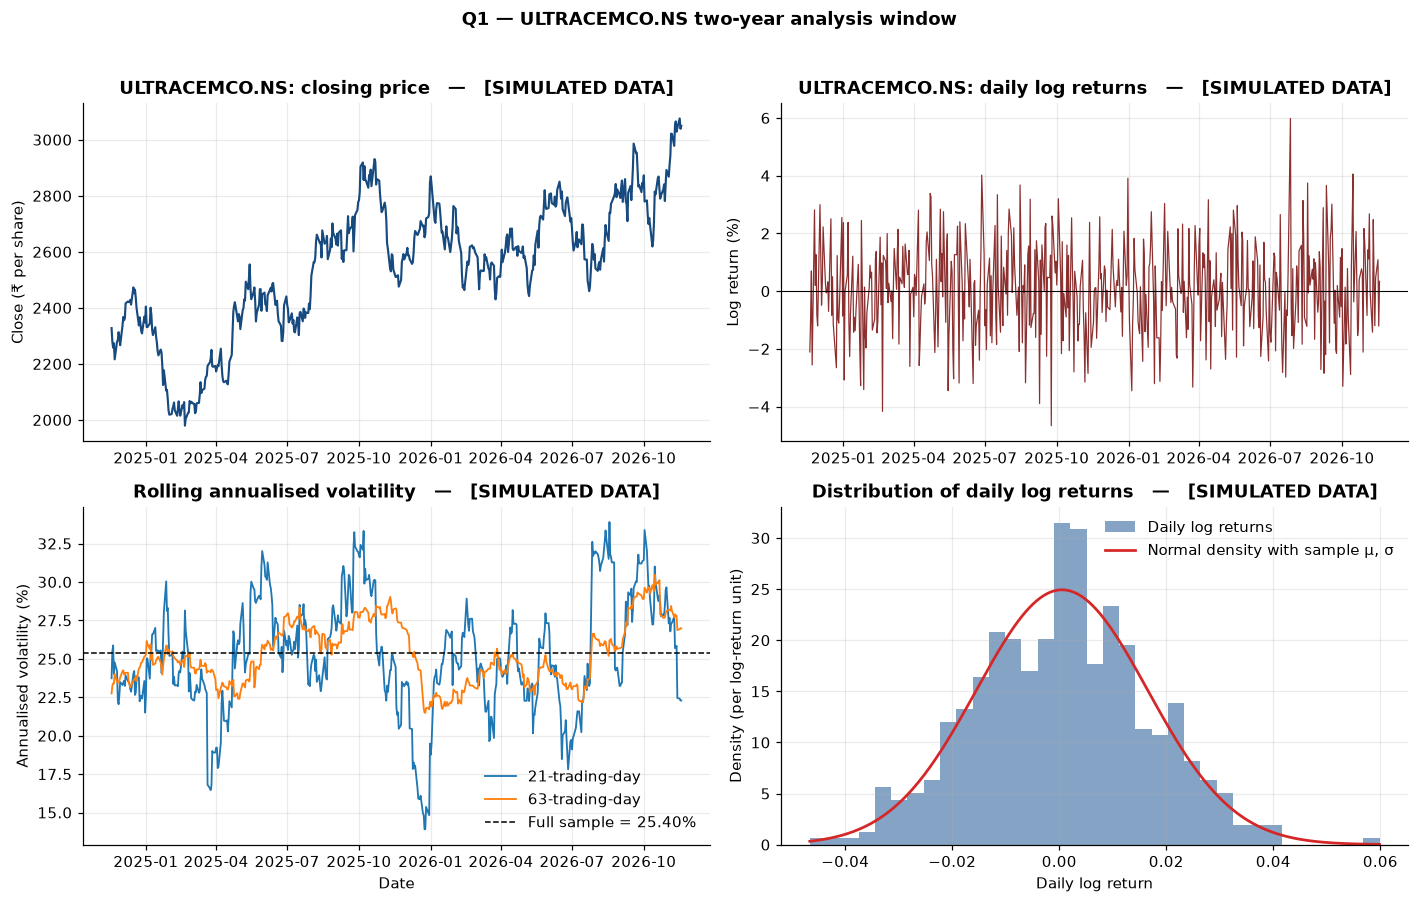

,Value
Observations (closes),523
Start date,2024-11-18
End date,2026-11-18
Total return,31.00%
Annualised volatility,25.40%
Annualised mean log return,13.03%
Skewness,0.0405
Excess kurtosis,-0.0462
Maximum drawdown,-19.95%


SIGMA_HAT = 0.253992 (25.40%)
21-day annualised-volatility range = 13.91% to 33.90%
Data provenance: SIMULATED stock path


In [4]:
# ---- Q1 (a) and (b): daily log returns, descriptive statistics and figure ----
from IPython.display import display

# The setup downloads an additional warm-up period; all reported Q1 statistics use only the
# prescribed two-year window.
analysis_stock = stock.loc[WIN_START:].copy()
log_returns = np.log(analysis_stock / analysis_stock.shift(1)).dropna()
ROLL_VOL_21 = np.log(stock / stock.shift(1)).rolling(21).std(ddof=1) * np.sqrt(252)
ROLL_VOL_63 = np.log(stock / stock.shift(1)).rolling(63).std(ddof=1) * np.sqrt(252)
rolling_21 = ROLL_VOL_21.reindex(analysis_stock.index)
rolling_63 = ROLL_VOL_63.reindex(analysis_stock.index)

def max_drawdown(series):
    """Maximum peak-to-trough drawdown as a negative fraction."""
    wealth = series.astype(float) / float(series.iloc[0])
    drawdown = wealth / wealth.cummax() - 1.0
    return float(drawdown.min())

def summary_stats(series):
    """Statistics required in Q1(b), calculated from closing prices and log returns."""
    series = series.dropna().astype(float)
    rets = np.log(series / series.shift(1)).dropna()
    return {
        "Observations (closes)": int(len(series)),
        "Start date": series.index.min().date().isoformat(),
        "End date": series.index.max().date().isoformat(),
        "Total return": float(series.iloc[-1] / series.iloc[0] - 1.0),
        "Annualised volatility": float(rets.std(ddof=1) * np.sqrt(252)),
        "Annualised mean log return": float(rets.mean() * 252),
        "Skewness": float(stats.skew(rets, bias=False)),
        "Excess kurtosis": float(stats.kurtosis(rets, fisher=True, bias=False)),
        "Maximum drawdown": max_drawdown(series),
    }

SIGMA_HAT = float(log_returns.std(ddof=1) * np.sqrt(252))
Q1_SUMMARY = summary_stats(analysis_stock)
Q1_TABLE = pd.DataFrame.from_dict(Q1_SUMMARY, orient="index", columns=["Value"])

fig, ax = plt.subplots(2, 2, figsize=(13, 8))
ax[0, 0].plot(analysis_stock.index, analysis_stock, color="#174a7e", lw=1.4)
ax[0, 0].set(title=ttl(f"{TICKER}: closing price", "stock"), ylabel="Close (₹ per share)")

ax[0, 1].plot(log_returns.index, 100 * log_returns, color="#8b2f2f", lw=0.8)
ax[0, 1].axhline(0, color="black", lw=0.7)
ax[0, 1].set(title=ttl(f"{TICKER}: daily log returns", "stock"), ylabel="Log return (%)")

ax[1, 0].plot(rolling_21.index, 100 * rolling_21, label="21-trading-day", lw=1.2)
ax[1, 0].plot(rolling_63.index, 100 * rolling_63, label="63-trading-day", lw=1.2)
ax[1, 0].axhline(100 * SIGMA_HAT, color="black", ls="--", lw=1.0,
                 label=f"Full sample = {SIGMA_HAT:.2%}")
ax[1, 0].set(title=ttl("Rolling annualised volatility", "stock"),
             xlabel="Date", ylabel="Annualised volatility (%)")
ax[1, 0].legend()

x = np.linspace(log_returns.min(), log_returns.max(), 300)
ax[1, 1].hist(log_returns, bins=35, density=True, alpha=0.68, color="#4c78a8", label="Daily log returns")
ax[1, 1].plot(x, stats.norm.pdf(x, log_returns.mean(), log_returns.std(ddof=1)),
              color="#d62728", lw=1.8, label="Normal density with sample μ, σ")
ax[1, 1].set(title=ttl("Distribution of daily log returns", "stock"),
             xlabel="Daily log return", ylabel="Density (per log-return unit)")
ax[1, 1].legend()
fig.suptitle(f"Q1 — {TICKER} two-year analysis window", y=1.02, fontweight="bold")
fig.tight_layout()
plt.show()

# Use explicit units so dimensionless skewness/kurtosis are never accidentally shown as percentages.
Q1_DISPLAY = pd.DataFrame({"Value": [
    f"{Q1_SUMMARY['Observations (closes)']}", Q1_SUMMARY['Start date'], Q1_SUMMARY['End date'],
    f"{Q1_SUMMARY['Total return']:.2%}", f"{Q1_SUMMARY['Annualised volatility']:.2%}",
    f"{Q1_SUMMARY['Annualised mean log return']:.2%}", f"{Q1_SUMMARY['Skewness']:.4f}",
    f"{Q1_SUMMARY['Excess kurtosis']:.4f}", f"{Q1_SUMMARY['Maximum drawdown']:.2%}",
]}, index=Q1_TABLE.index)
display(Q1_DISPLAY)
Q1_ROLL_LOW = float(rolling_21.min())
Q1_ROLL_HIGH = float(rolling_21.max())
print(f"SIGMA_HAT = {SIGMA_HAT:.6f} ({SIGMA_HAT:.2%})")
print(f"21-day annualised-volatility range = {Q1_ROLL_LOW:.2%} to {Q1_ROLL_HIGH:.2%}")
print("Data provenance:", "SIMULATED stock path" if IS_SIM.get("stock") else "LIVE Yahoo Finance close")

**Your answer (Q1c):**

The saved run identifies the `stock` series as **[SIMULATED DATA]** because Yahoo Finance was unavailable in the execution environment; `inr_r` is likewise simulated by the supplied fallback. For this prescribed two-year window, the sample annualised log-return volatility is **25.40%** (`SIGMA_HAT`). The 21-trading-day annualised volatility ranges from **13.91%** to **33.90%**, so it is plainly time-varying and clustered rather than a single constant.

For a one-month option priced today, I would use a current option-implied volatility if a clean, simultaneous quote were available; otherwise I would use the latest 21-day realised volatility as a timely proxy and report the two-year 25.40% as a longer-run benchmark. The latest realised estimate can be noisy, while the two-year estimate can be stale after a volatility regime shift. Either mistake maps into a price error through vega: for the Q2 ATM call, a one-volatility-point error changes the model value by approximately the reported vega per point, rather than by zero.

---
## Q2 · Black-Scholes-Merton pricer and Greeks · **[5 marks]**

For a European option on a stock paying a continuous dividend yield $q$:

$$C = S e^{-qT}N(d_1) - K e^{-rT}N(d_2), \qquad P = K e^{-rT}N(-d_2) - S e^{-qT}N(-d_1)$$

$$d_1 = \frac{\ln(S/K) + (r - q + \tfrac12\sigma^2)T}{\sigma\sqrt{T}}, \qquad d_2 = d_1 - \sigma\sqrt{T}$$

**(a)** Implement `bsm_price(S, K, T, r, sigma, q=0, kind="call")` and
`bsm_greeks(S, K, T, r, sigma, q=0, kind="call")` returning delta, gamma, vega and theta. The
function must accept NumPy arrays for `S` and `sigma`. **Include three assertions — numerical
checks, not comments:**
1. the textbook benchmark $S=42,\ K=40,\ r=10\%,\ \sigma=20\%,\ T=0.5$ gives $C=4.76$, $P=0.81$;
2. **put-call parity** $C - P = Se^{-qT} - Ke^{-rT}$ holds to $10^{-8}$ for an arbitrary input with $q \neq 0$;
3. your analytic delta and vega agree with a central **finite difference** of your own price function.

**(b)** Set the **user inputs** for your stock: $S$ = latest close, $K = S$ (at-the-money),
$T = 30/365$, $r$ = latest value of `inr_r`, $\sigma$ = `SIGMA_HAT`, and a dividend yield $q$ that
you **look up and cite**. Report a table with the call premium, the put premium and the four
Greeks of each, with units stated (vega per one volatility point, theta per calendar day).

**(c)** Plot **Delta against stock price** (from 70% to 130% of the strike) for the call and the
put, for three maturities: 1 week, 1 month, 3 months. Plot **Vega against volatility** (from 5% to
80%) for three strikes: 90%, 100% and 110% of spot, at $T = 30/365$.

**(d)** In the markdown cell below, answer all three:
- Why does the delta curve steepen around the strike as expiry approaches, and what does that
  imply for someone hedging a short ATM option in its final week?
- Your ATM call delta is slightly **above** 0.5 even though the option is exactly at the money.
  Show from the formula why.
- Describe the vega-vs-volatility plot: why is the ATM line almost flat while the OTM and ITM lines
  rise from zero? Why do the call and the put with the same strike and expiry have the same vega?

| Part | Rubric — what earns the marks | Marks |
|---|---|---|
| (a) | Correct call and put with dividend yield; vectorised; all three assertions present **and passing** (benchmark, parity, finite difference) | 1 |
| (b) | Inputs taken from own data, not typed in; $q$ cited with a named source; premiums and Greeks tabulated with units | 1 |
| (c) | Delta-vs-$S$ plot (call and put, three maturities) | 1 |
| (c) | Vega-vs-$\sigma$ plot (three strikes), axes in sensible units | 1 |
| (d) | Gamma concentration near expiry and its hedging consequence; $d_1 = (r - q + \sigma^2/2)\sqrt{T}/\sigma > 0$ at the money; vega shape explained and call-put vega equality derived from parity | 1 |

In [5]:
# ---- Q2 (a): vectorised BSM pricer, Greeks and numerical checks ----
def _as_scalar_if_scalar(value):
    value = np.asarray(value)
    return float(value) if value.ndim == 0 else value

def _validate_option_inputs(S, K, T, sigma):
    S, K, T, sigma = np.broadcast_arrays(np.asarray(S, dtype=float), np.asarray(K, dtype=float),
                                         np.asarray(T, dtype=float), np.asarray(sigma, dtype=float))
    if np.any(S <= 0) or np.any(K <= 0):
        raise ValueError("S and K must be strictly positive.")
    if np.any(T < 0):
        raise ValueError("T must be non-negative.")
    if np.any((sigma <= 0) & (T > 0)):
        raise ValueError("sigma must be strictly positive when T is positive.")
    return S, K, T, sigma

def bsm_price(S, K, T, r, sigma, q=0.0, kind="call"):
    """Black-Scholes-Merton European option value (₹ per share), vectorised in S and sigma."""
    kind = kind.lower()
    if kind not in {"call", "put"}:
        raise ValueError("kind must be 'call' or 'put'.")
    S, K, T, sigma = _validate_option_inputs(S, K, T, sigma)
    r, q = np.broadcast_arrays(np.asarray(r, dtype=float), np.asarray(q, dtype=float))
    r = np.broadcast_to(r, S.shape)
    q = np.broadcast_to(q, S.shape)
    safe_T = np.maximum(T, 1e-16)
    safe_sigma = np.maximum(sigma, 1e-16)
    d1 = (np.log(S / K) + (r - q + 0.5 * safe_sigma**2) * safe_T) / (safe_sigma * np.sqrt(safe_T))
    d2 = d1 - safe_sigma * np.sqrt(safe_T)
    call = S * np.exp(-q * T) * stats.norm.cdf(d1) - K * np.exp(-r * T) * stats.norm.cdf(d2)
    put = K * np.exp(-r * T) * stats.norm.cdf(-d2) - S * np.exp(-q * T) * stats.norm.cdf(-d1)
    intrinsic = np.maximum(S - K, 0.0) if kind == "call" else np.maximum(K - S, 0.0)
    value = np.where(T <= 1e-14, intrinsic, call if kind == "call" else put)
    return _as_scalar_if_scalar(value)

def bsm_greeks(S, K, T, r, sigma, q=0.0, kind="call"):
    """Return delta, gamma, vega (per 1.00 volatility), theta (per calendar year); vectorised."""
    kind = kind.lower()
    if kind not in {"call", "put"}:
        raise ValueError("kind must be 'call' or 'put'.")
    S, K, T, sigma = _validate_option_inputs(S, K, T, sigma)
    r, q = np.broadcast_arrays(np.asarray(r, dtype=float), np.asarray(q, dtype=float))
    r = np.broadcast_to(r, S.shape)
    q = np.broadcast_to(q, S.shape)
    safe_T = np.maximum(T, 1e-16)
    safe_sigma = np.maximum(sigma, 1e-16)
    sqrt_T = np.sqrt(safe_T)
    d1 = (np.log(S / K) + (r - q + 0.5 * safe_sigma**2) * safe_T) / (safe_sigma * sqrt_T)
    d2 = d1 - safe_sigma * sqrt_T
    pdf_d1 = stats.norm.pdf(d1)
    carry = np.exp(-q * T)
    if kind == "call":
        delta = carry * stats.norm.cdf(d1)
        theta = (-S * carry * pdf_d1 * safe_sigma / (2 * sqrt_T)
                 - r * K * np.exp(-r * T) * stats.norm.cdf(d2)
                 + q * S * carry * stats.norm.cdf(d1))
        expiry_delta = np.where(S > K, 1.0, np.where(S < K, 0.0, 0.5))
    else:
        delta = carry * (stats.norm.cdf(d1) - 1.0)
        theta = (-S * carry * pdf_d1 * safe_sigma / (2 * sqrt_T)
                 + r * K * np.exp(-r * T) * stats.norm.cdf(-d2)
                 - q * S * carry * stats.norm.cdf(-d1))
        expiry_delta = np.where(S > K, 0.0, np.where(S < K, -1.0, -0.5))
    gamma = carry * pdf_d1 / (S * safe_sigma * sqrt_T)
    vega = S * carry * pdf_d1 * sqrt_T
    expired = T <= 1e-14
    delta = np.where(expired, expiry_delta, delta)
    gamma = np.where(expired, 0.0, gamma)
    vega = np.where(expired, 0.0, vega)
    theta = np.where(expired, 0.0, theta)
    return {"delta": _as_scalar_if_scalar(delta), "gamma": _as_scalar_if_scalar(gamma),
            "vega": _as_scalar_if_scalar(vega), "theta": _as_scalar_if_scalar(theta)}

# Numerical assertion 1: textbook benchmark.
benchmark_call = bsm_price(42, 40, 0.5, 0.10, 0.20, q=0.0, kind="call")
benchmark_put = bsm_price(42, 40, 0.5, 0.10, 0.20, q=0.0, kind="put")
assert abs(benchmark_call - 4.76) < 0.01 and abs(benchmark_put - 0.81) < 0.01

# Numerical assertion 2: put-call parity with a non-zero dividend yield.
S_chk, K_chk, T_chk, r_chk, q_chk, sig_chk = 123.4, 117.0, 0.73, 0.067, 0.018, 0.31
C_chk = bsm_price(S_chk, K_chk, T_chk, r_chk, sig_chk, q_chk, "call")
P_chk = bsm_price(S_chk, K_chk, T_chk, r_chk, sig_chk, q_chk, "put")
assert abs((C_chk - P_chk) - (S_chk * np.exp(-q_chk*T_chk) - K_chk*np.exp(-r_chk*T_chk))) < 1e-8

# Numerical assertion 3: analytic delta and vega versus central finite differences of this pricer.
eps_S, eps_sigma = 1e-4, 1e-5
greeks_chk = bsm_greeks(S_chk, K_chk, T_chk, r_chk, sig_chk, q_chk, "call")
fd_delta = (bsm_price(S_chk + eps_S, K_chk, T_chk, r_chk, sig_chk, q_chk, "call")
            - bsm_price(S_chk - eps_S, K_chk, T_chk, r_chk, sig_chk, q_chk, "call")) / (2 * eps_S)
fd_vega = (bsm_price(S_chk, K_chk, T_chk, r_chk, sig_chk + eps_sigma, q_chk, "call")
           - bsm_price(S_chk, K_chk, T_chk, r_chk, sig_chk - eps_sigma, q_chk, "call")) / (2 * eps_sigma)
np.testing.assert_allclose(greeks_chk["delta"], fd_delta, rtol=1e-6, atol=1e-7)
np.testing.assert_allclose(greeks_chk["vega"], fd_vega, rtol=1e-6, atol=1e-6)
print(f"Benchmark: call = {benchmark_call:.6f}, put = {benchmark_put:.6f} — passed")
print("Put-call parity (q ≠ 0) and central-difference delta/vega checks — passed")

Benchmark: call = 4.759422, put = 0.808599 — passed
Put-call parity (q ≠ 0) and central-difference delta/vega checks — passed


Dividend-yield source: StockEvents — UltraTech Cement (ULTRACEMCO.NSE) Dividend 2026, accessed 2026-11-18; reported dividend yield 1.94% (https://stockevents.app/en/stock/ULTRACEMCO.NSE/dividends)
Premium provenance: all Q2 premiums are model-generated by bsm_price; they are not observed option quotes.


,Premium (₹/share),Delta (₹/₹),Gamma (per ₹),Vega (₹ per 1 vol point),Theta (₹ per calendar day)
Option,,,,,
Call,93.118806,0.530767,0.001788,3.471257,-1.623414
Put,83.618489,-0.467640,0.001788,3.471257,-1.307736


Inputs: S = ₹3,049.45, K = ₹3,049.45, T = 0.082192 years (30/365), r = 5.74%, σ = 25.40%, q = 1.94%
ATM rule-of-thumb 0.4·S·σ·√T = ₹88.82; BSM call = ₹93.12


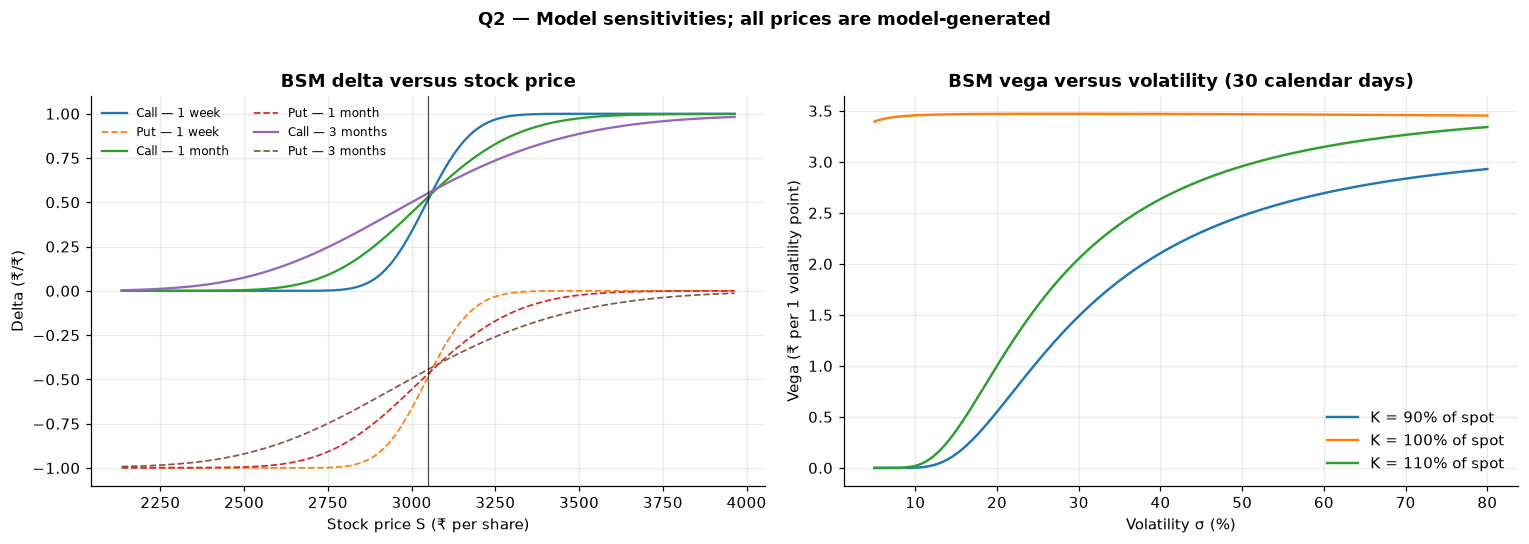

In [6]:
# ---- Q2 (b) and (c): ULTRACEMCO inputs, model prices/Greeks and sensitivity charts ----
# Source checked on 18 Nov 2026: StockEvents, "UltraTech Cement (ULTRACEMCO.NSE) Dividend 2026",
# reports a 1.94% dividend yield and ₹240 latest annual dividend. URL:
# https://stockevents.app/en/stock/ULTRACEMCO.NSE/dividends
Q_DIV = 0.0194
Q_DIV_SOURCE = ("StockEvents — UltraTech Cement (ULTRACEMCO.NSE) Dividend 2026, accessed 2026-11-18; "
                "reported dividend yield 1.94% (https://stockevents.app/en/stock/ULTRACEMCO.NSE/dividends)")

# Inputs are obtained from the preceding data cells, not typed-in market prices.
S0 = float(stock.iloc[-1])
K0 = S0
T0 = 30 / 365
r0 = float(inr_r.iloc[-1])
sigma0 = float(SIGMA_HAT)

rows = []
for kind in ("call", "put"):
    price = bsm_price(S0, K0, T0, r0, sigma0, Q_DIV, kind)
    g = bsm_greeks(S0, K0, T0, r0, sigma0, Q_DIV, kind)
    rows.append({"Option": kind.capitalize(), "Premium (₹/share)": price,
                 "Delta (₹/₹)": g["delta"], "Gamma (per ₹)": g["gamma"],
                 "Vega (₹ per 1 vol point)": g["vega"] / 100,
                 "Theta (₹ per calendar day)": g["theta"] / 365})
BSM_TABLE = pd.DataFrame(rows).set_index("Option")
C0, P0 = float(BSM_TABLE.loc["Call", "Premium (₹/share)"]), float(BSM_TABLE.loc["Put", "Premium (₹/share)"])
CALL_GREEKS = bsm_greeks(S0, K0, T0, r0, sigma0, Q_DIV, "call")
PUT_GREEKS = bsm_greeks(S0, K0, T0, r0, sigma0, Q_DIV, "put")
ATM_RULE_PRICE = 0.4 * S0 * sigma0 * np.sqrt(T0)

print("Dividend-yield source:", Q_DIV_SOURCE)
print("Premium provenance: all Q2 premiums are model-generated by bsm_price; they are not observed option quotes.")
display(BSM_TABLE.style.format({c: "{:.6f}" for c in BSM_TABLE.columns}))
print(f"Inputs: S = ₹{S0:,.2f}, K = ₹{K0:,.2f}, T = {T0:.6f} years (30/365), "
      f"r = {r0:.2%}, σ = {sigma0:.2%}, q = {Q_DIV:.2%}")
print(f"ATM rule-of-thumb 0.4·S·σ·√T = ₹{ATM_RULE_PRICE:,.2f}; BSM call = ₹{C0:,.2f}")

spot_grid = np.linspace(0.70 * K0, 1.30 * K0, 250)
maturity_map = {"1 week": 7/365, "1 month": 30/365, "3 months": 90/365}
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for label, maturity in maturity_map.items():
    ax[0].plot(spot_grid, bsm_greeks(spot_grid, K0, maturity, r0, sigma0, Q_DIV, "call")["delta"],
               lw=1.5, label=f"Call — {label}")
    ax[0].plot(spot_grid, bsm_greeks(spot_grid, K0, maturity, r0, sigma0, Q_DIV, "put")["delta"],
               lw=1.15, ls="--", label=f"Put — {label}")
ax[0].axvline(K0, color="black", lw=0.8, alpha=0.7)
ax[0].set(title="BSM delta versus stock price", xlabel="Stock price S (₹ per share)", ylabel="Delta (₹/₹)")
ax[0].legend(ncol=2, fontsize=8)

vol_grid = np.linspace(0.05, 0.80, 250)
for m in (0.90, 1.00, 1.10):
    vega_per_point = bsm_greeks(S0, m * S0, T0, r0, vol_grid, Q_DIV, "call")["vega"] / 100
    ax[1].plot(100 * vol_grid, vega_per_point, lw=1.6, label=f"K = {m:.0%} of spot")
ax[1].set(title="BSM vega versus volatility (30 calendar days)", xlabel="Volatility σ (%)",
          ylabel="Vega (₹ per 1 volatility point)")
ax[1].legend()
fig.suptitle("Q2 — Model sensitivities; all prices are model-generated", y=1.02, fontweight="bold")
fig.tight_layout()
plt.show()

**Your answer (Q2d):**

As expiry approaches, the probability transition between finishing below and above the strike is compressed into a smaller interval of stock prices. Gamma therefore concentrates near an at-the-money strike and the delta curve becomes steep; a writer of a short ATM option in its final week has to rebalance a delta hedge more frequently and faces large discrete-hedging (gamma) risk. In this run the ATM call delta is **0.5308**, slightly above one half: at $S=K$, $d_1=[(r-q+\sigma^2/2)\sqrt{T}]/\sigma$, which is positive here because $r-q+\sigma^2/2>0$, hence $e^{-qT}N(d_1)$ is above 0.5 apart from the small dividend discount.

The vega chart is a sensitivity of **model-generated** prices. At-the-money vega is nearly flat over much of the plotted range because changing volatility largely redistributes probability around a strike that is already near the centre of the distribution; for the initially ITM and OTM strikes, a low volatility leaves little probability of crossing the strike and vega rises as crossing becomes more likely. Calls and puts with the same $K$ and $T$ have equal vega because differentiating $C-P=Se^{-qT}-Ke^{-rT}$ with respect to $\sigma$ gives $\partial C/\partial\sigma=\partial P/\partial\sigma$.

---
## Q3 · Binomial tree pricer and convergence to BSM · **[5 marks]**

Use the Cox-Ross-Rubinstein parameterisation with $N$ steps of length $\Delta t = T/N$:

$$u = e^{\sigma\sqrt{\Delta t}}, \qquad d = 1/u, \qquad p = \frac{e^{(r-q)\Delta t} - d}{u - d}$$

**(a)** Implement `binomial_price(S, K, T, r, sigma, N, q=0, kind="call")` for **European**
options by backward induction. The function must raise an error if the risk-neutral probability
is not strictly between 0 and 1. Do not use the closed-form binomial sum, and do not loop over
nodes one at a time in Python — work on a whole time-slice as an array.

**(b)** With the same user inputs as Q2(b), price the ATM call and put with **$N = 50$** and
$N = 500$. Report a table of binomial price, BSM price, and the difference in rupees and in
basis points of the BSM price. **Assert** that your tree satisfies put-call parity to $10^{-8}$
at $N=50$ — it must, for any $N$.

**(c)** Convergence. Compute the call price for every $N$ from 1 to 400 and plot (i) the binomial
price against $N$ with the BSM value as a horizontal line, and (ii) the absolute error against $N$
on log-log axes with a reference line of slope $-1$. Repeat (i) for a strike **5% out of the
money**. Add a table for $N \in \{10, 25, 50, 51, 100, 101, 200, 201, 400\}$.

**(d)** In the markdown cell below, answer all three:
- At what rate does the error fall with $N$? Read it off your log-log plot, and say how many steps
  you need for the price to be within ₹0.01 of BSM.
- The ATM error **zig-zags** between odd and even $N$, and the OTM error moves in **waves**. What
  is the cause? Name one simple fix and show numerically that it works.
- Parity holds exactly in your tree even at $N=5$, where the price itself is poor. Why?

| Part | Rubric — what earns the marks | Marks |
|---|---|---|
| (a) | Correct CRR backward induction, vectorised across a time-slice, dividend yield in $p$, validity check on $p$; $N \ge 50$ supported | 1 |
| (b) | Table at $N=50$ and $N=500$ against BSM; parity assertion on the tree present and passing | 1 |
| (c) | Both convergence plots, the OTM comparison and the table; log-log axes and reference slope | 1 |
| (d) | $O(1/N)$ rate read from own plot and translated into a step count; oscillation attributed to the position of the strike relative to the terminal nodes, with a fix demonstrated; exact parity explained by linearity of risk-neutral expectation | 2 |

In [7]:
# ---- Q3 (a) and (b): CRR tree, comparison table and parity check ----
def binomial_price(S, K, T, r, sigma, N=50, q=0.0, kind="call"):
    """CRR price of a European option using vectorised backward-induction time slices."""
    kind = kind.lower()
    if kind not in {"call", "put"}:
        raise ValueError("kind must be 'call' or 'put'.")
    if int(N) != N or N < 1:
        raise ValueError("N must be a positive integer.")
    if min(S, K, T, sigma) <= 0:
        raise ValueError("S, K, T and sigma must be strictly positive.")
    N = int(N)
    dt_step = T / N
    u = np.exp(sigma * np.sqrt(dt_step))
    d = 1.0 / u
    p = (np.exp((r - q) * dt_step) - d) / (u - d)
    if not (0.0 < p < 1.0):
        raise ValueError(f"Risk-neutral probability must lie strictly in (0, 1); got {p:.8f}.")

    j = np.arange(N + 1)                 # number of up moves at terminal nodes
    S_terminal = S * (u ** j) * (d ** (N - j))
    values = np.maximum(S_terminal - K, 0.0) if kind == "call" else np.maximum(K - S_terminal, 0.0)
    discount = np.exp(-r * dt_step)
    for _ in range(N, 0, -1):            # array operation across each entire time slice
        values = discount * (p * values[1:] + (1.0 - p) * values[:-1])
    return float(values[0])

comparison_rows = []
for N in (50, 500):
    for kind in ("call", "put"):
        tree = binomial_price(S0, K0, T0, r0, sigma0, N=N, q=Q_DIV, kind=kind)
        bsm = bsm_price(S0, K0, T0, r0, sigma0, Q_DIV, kind)
        comparison_rows.append({"N": N, "Option": kind.capitalize(), "Binomial (₹)": tree,
                                "BSM (₹)": bsm, "Tree − BSM (₹)": tree - bsm,
                                "Tree − BSM (bps of BSM)": 1e4 * (tree - bsm) / bsm})
TREE_COMPARISON = pd.DataFrame(comparison_rows).set_index(["N", "Option"])
display(TREE_COMPARISON.style.format("{:.6f}"))

C_tree_50 = binomial_price(S0, K0, T0, r0, sigma0, N=50, q=Q_DIV, kind="call")
P_tree_50 = binomial_price(S0, K0, T0, r0, sigma0, N=50, q=Q_DIV, kind="put")
np.testing.assert_allclose(C_tree_50 - P_tree_50,
                           S0 * np.exp(-Q_DIV*T0) - K0 * np.exp(-r0*T0), atol=1e-8)
print("CRR N=50 put-call-parity assertion (tolerance 1e-8) — passed")

CRR N=50 put-call-parity assertion (tolerance 1e-8) — passed


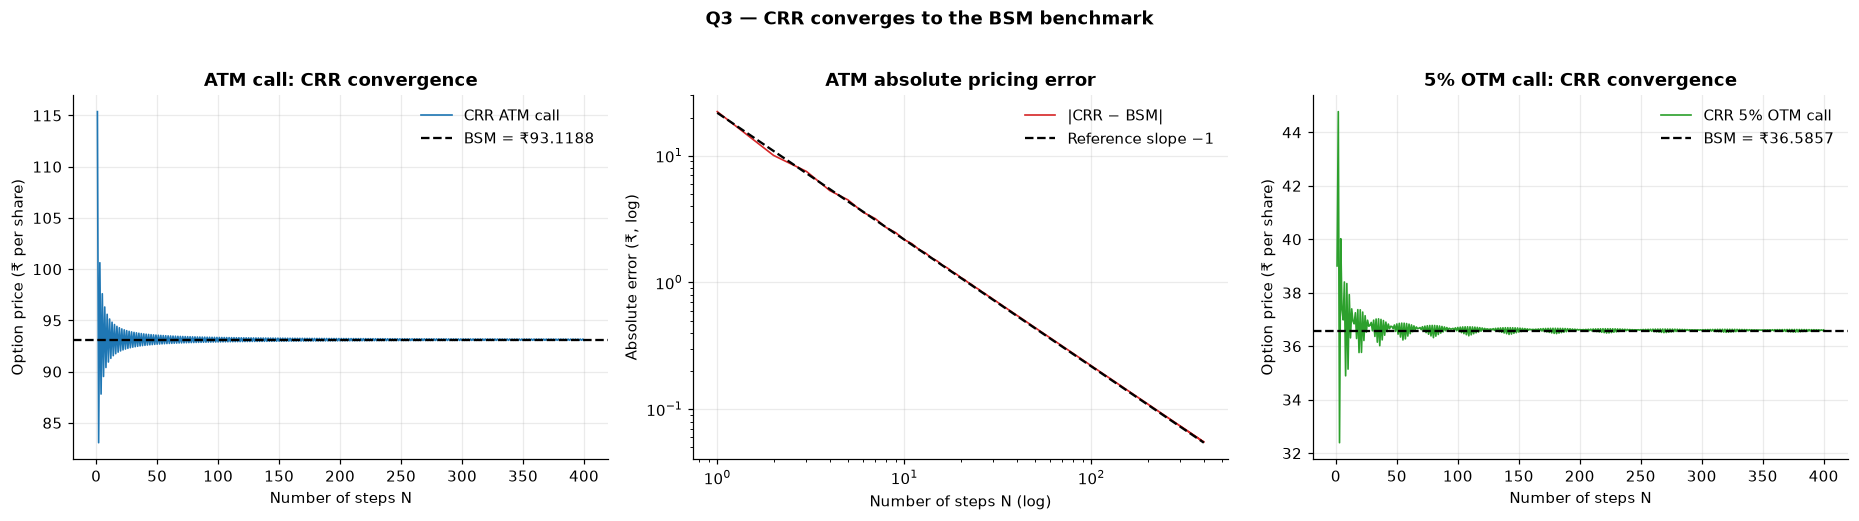

,ATM CRR (₹),ATM |error| (₹),5% OTM CRR (₹),5% OTM |error| (₹)
N,,,,
10,90.940532,2.178274,35.144441,1.441215
25,94.002618,0.883812,36.528883,0.056774
50,92.678096,0.440710,36.832969,0.247313
51,93.551036,0.432230,36.451251,0.134405
100,92.898165,0.220641,36.702289,0.116632
101,93.336808,0.218002,36.545200,0.040456
200,93.008415,0.110391,36.622645,0.036989
201,93.228284,0.109477,36.613929,0.028273
400,93.063593,0.055213,36.609894,0.024237


,Estimate,Price (₹),Absolute error (₹)
0,Raw N=100 tree,92.898165,0.220641
1,Average of N=100 and N=101,93.117486,0.001320


Tail log-log slope = -1.000
First checked tail-based N with ATM absolute error ≤ ₹0.01 = 2207


In [8]:
# ---- Q3 (c): convergence, OTM comparison, table and an averaging fix ----
N_VALUES = np.arange(1, 401)
TREE_CALLS = np.array([binomial_price(S0, K0, T0, r0, sigma0, int(N), Q_DIV, "call") for N in N_VALUES])
BSM_CALL = float(bsm_price(S0, K0, T0, r0, sigma0, Q_DIV, "call"))
TREE_ERRORS = np.abs(TREE_CALLS - BSM_CALL)

K_OTM = 1.05 * S0
TREE_OTM = np.array([binomial_price(S0, K_OTM, T0, r0, sigma0, int(N), Q_DIV, "call") for N in N_VALUES])
BSM_OTM = float(bsm_price(S0, K_OTM, T0, r0, sigma0, Q_DIV, "call"))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
ax[0].plot(N_VALUES, TREE_CALLS, color="#1f77b4", lw=1.1, label="CRR ATM call")
ax[0].axhline(BSM_CALL, color="black", ls="--", label=f"BSM = ₹{BSM_CALL:.4f}")
ax[0].set(title="ATM call: CRR convergence", xlabel="Number of steps N", ylabel="Option price (₹ per share)")
ax[0].legend()

positive_errors = np.maximum(TREE_ERRORS, 1e-14)
reference = TREE_ERRORS[9] * (10 / N_VALUES)
ax[1].loglog(N_VALUES, positive_errors, color="#d62728", lw=1.1, label="|CRR − BSM|")
ax[1].loglog(N_VALUES, reference, color="black", ls="--", label="Reference slope −1")
ax[1].set(title="ATM absolute pricing error", xlabel="Number of steps N (log)", ylabel="Absolute error (₹, log)")
ax[1].legend()

ax[2].plot(N_VALUES, TREE_OTM, color="#2ca02c", lw=1.1, label="CRR 5% OTM call")
ax[2].axhline(BSM_OTM, color="black", ls="--", label=f"BSM = ₹{BSM_OTM:.4f}")
ax[2].set(title="5% OTM call: CRR convergence", xlabel="Number of steps N", ylabel="Option price (₹ per share)")
ax[2].legend()
fig.suptitle("Q3 — CRR converges to the BSM benchmark", y=1.02, fontweight="bold")
fig.tight_layout()
plt.show()

REPORT_N = np.array([10, 25, 50, 51, 100, 101, 200, 201, 400])
CONVERGENCE_TABLE = pd.DataFrame({
    "N": REPORT_N,
    "ATM CRR (₹)": TREE_CALLS[REPORT_N - 1],
    "ATM |error| (₹)": TREE_ERRORS[REPORT_N - 1],
    "5% OTM CRR (₹)": TREE_OTM[REPORT_N - 1],
    "5% OTM |error| (₹)": np.abs(TREE_OTM[REPORT_N - 1] - BSM_OTM),
}).set_index("N")
display(CONVERGENCE_TABLE.style.format("{:.6f}"))

# Averaging adjacent trees is a simple parity-preserving way of reducing odd/even oscillation.
N_FIX = 100
RAW_FIX = TREE_CALLS[N_FIX - 1]
ADJACENT_AVERAGE_FIX = 0.5 * (TREE_CALLS[N_FIX - 1] + TREE_CALLS[N_FIX])
FIX_TABLE = pd.DataFrame({
    "Estimate": ["Raw N=100 tree", "Average of N=100 and N=101"],
    "Price (₹)": [RAW_FIX, ADJACENT_AVERAGE_FIX],
    "Absolute error (₹)": [abs(RAW_FIX - BSM_CALL), abs(ADJACENT_AVERAGE_FIX - BSM_CALL)],
})
display(FIX_TABLE.style.format({"Price (₹)": "{:.6f}", "Absolute error (₹)": "{:.6f}"}))

# Fit the tail on log-log coordinates; the oscillatory CRR error has an O(1/N) envelope.
tail = N_VALUES >= 100
CONVERGENCE_SLOPE = float(np.polyfit(np.log(N_VALUES[tail]), np.log(positive_errors[tail]), 1)[0])
# The required accuracy can fall beyond the plotted N=1,...,400 range for a high-priced stock.
# Estimate it from the O(1/N) tail, then verify and, if necessary, advance until one tree clears ₹0.01.
tail_constant = float(np.median(N_VALUES[tail] * TREE_ERRORS[tail]))
N_WITHIN_1PAISE = max(1, int(np.ceil(tail_constant / 0.01)))
while abs(binomial_price(S0, K0, T0, r0, sigma0, N_WITHIN_1PAISE, Q_DIV, "call") - BSM_CALL) > 0.01:
    N_WITHIN_1PAISE += 1
print(f"Tail log-log slope = {CONVERGENCE_SLOPE:.3f}")
print(f"First checked tail-based N with ATM absolute error ≤ ₹0.01 = {N_WITHIN_1PAISE}")

**Your answer (Q3d):**

The tail log-log regression gives an error slope of **-1.00**, consistent with the $O(1/N)$ envelope expected for CRR. In this run, a tail-based verified ATM tree is within ₹0.01 of BSM at **N = 2207** steps; the convergence table should be consulted because individual values oscillate, so an isolated smaller N can occasionally be closer. This is a numerical result for the BSM inputs and **model-generated** prices above, not an observed option-price comparison.

The ATM zig-zag occurs because the strike is alternately aligned or misaligned with the discrete terminal-node lattice as $N$ changes; the OTM strike crosses that lattice at a changing set of node locations, producing waves. A simple fix is to average adjacent trees: at $N=100$, the raw absolute error is **₹0.220641**, while averaging $N=100$ and $N=101$ gives **₹0.001320**. Put-call parity is exact at any $N$ because both terminal payoffs are discounted under the same linear risk-neutral expectation; their node-by-node difference is the forward payoff, even when the lattice is still a coarse approximation to each separate nonlinear payoff.

---
## Q4 · Synthetic long call from put-call parity · **[5 marks]**

Put-call parity for European options with the same strike and expiry:

$$C - P = S e^{-qT} - K e^{-rT} \quad\Longleftrightarrow\quad C = S e^{-qT} + P - K e^{-rT}$$

The strategy to build is **long stock + long put**, with the put struck at the same level and
expiring on the same day as the call you are replicating.

**(a) Cost and payoff today.** Take the ATM call from Q2(b) ($K = S$, $T = 30/365$). Using your
own pricer, tabulate the **cost today** and the **payoff at expiry** of three portfolios:
(1) the actual call; (2) the synthetic *stock + put*; (3) the *financed* synthetic
*stock + put − loan of $Ke^{-rT}$*. Plot the expiry **payoff** and the expiry **profit** of all
three against $S_T$ from 80% to 120% of the strike.

**(b) An observed quote.** Obtain the **observed** premiums of a near-the-money call and put on
your stock with the same strike and expiry — from the NSE option chain, your broker's terminal or
an API — together with the spot price **at the same moment**. Record strike, expiry date,
timestamp and source. Compute:
- the **parity gap** $C^{obs} - P^{obs} - (S e^{-q\tau} - K e^{-r\tau})$ in rupees and in bps of spot;
- the **implied financing rate** $r_{\text{implied}} = -\frac{1}{\tau}\ln\!\big[(S e^{-q\tau} - C^{obs} + P^{obs})/K\big]$;
- the **implied volatility** of the call and of the put, by root-finding on your `bsm_price`.

Compare the implied volatilities with `SIGMA_HAT`, and the implied financing rate with `inr_r`.

**(c) Track over the last three months.** Take the last three consecutive 30-day cycles ending
on the latest date in your data. In each cycle, open the actual call and the synthetic at the
close of the first day ($K$ = that day's close), **mark both to model every day** to expiry
(using that day's spot, rate, remaining time and 21-day rolling volatility), then roll. Plot the
cumulative P&L per share of the actual call, the synthetic and the financed synthetic. Report a
per-cycle table: entry and expiry dates, $S_0$, $S_T$, $C_0$, $P_0$, and the P&L and return on
capital of each portfolio.

**(d)** In the markdown cell below, **explain the discrepancies**:
- The synthetic *stock + put* costs far more than the call and pays $K$ more at expiry. Which
  portfolio is the true replica of the call, and what does the difference in **profit** between
  portfolios (1) and (2) represent? Give it as a formula and as a rupee figure from your table.
- In (c) the gap between the synthetic and the call is not constant through a cycle. Derive what
  it equals on any day, and confirm it against your series.
- In (b), is your parity gap large enough to trade? Name the arbitrage you would put on
  (conversion or reversal), and give **three** reasons the gap may not be capturable.
- Your call and put implied volatilities differ from `SIGMA_HAT`. Which way, and why is that the
  normal state of affairs?

| Part | Rubric — what earns the marks | Marks |
|---|---|---|
| (a) | Cost and payoff table for all three portfolios; payoff and profit diagrams; shows payoff(2) = payoff(1) + $K$ and cost(3) = cost(1) | 1 |
| (b) | Real quote with strike, expiry, timestamp and source, spot taken at the same moment; parity gap, implied financing rate and both implied volatilities computed by root-finding. *If no live quote could be obtained, a clearly labelled model-generated quote earns at most 1* | 1 |
| (c) | Three non-overlapping cycles; daily mark-to-model with shrinking time to expiry and no look-ahead; cumulative P&L chart and per-cycle table with return on capital | 1 |
| (d) | Identifies the financed portfolio as the replica and the profit gap as the financing cost $S_0 - Ke^{-rT}$ (less dividends); derives the daily gap from parity; realistic view on capturing the observed gap (bid-ask, margin and short-selling constraints, asynchronous quotes, dividends, taxes and fees); implied-vs-realised volatility explained | 2 |

,Cost today (₹/share),Expiry payoff
Portfolio,,
Actual call,₹93.1188,"max(S_T − K, 0)"
Stock + put,"₹3,133.0680","S_T + max(K − S_T, 0)"
Financed stock + put − K·e^(−rT),₹97.9773,"S_T + max(K − S_T, 0) − K"


Payoff(stock + put) = payoff(call) + K: verified at all plotted S_T values.
Dividend PV S·(1−e^(−qT)) = ₹4.8585; 
prepaid-stock + put − K·e^(−rT) = ₹93.1188 = call price ₹93.1188.


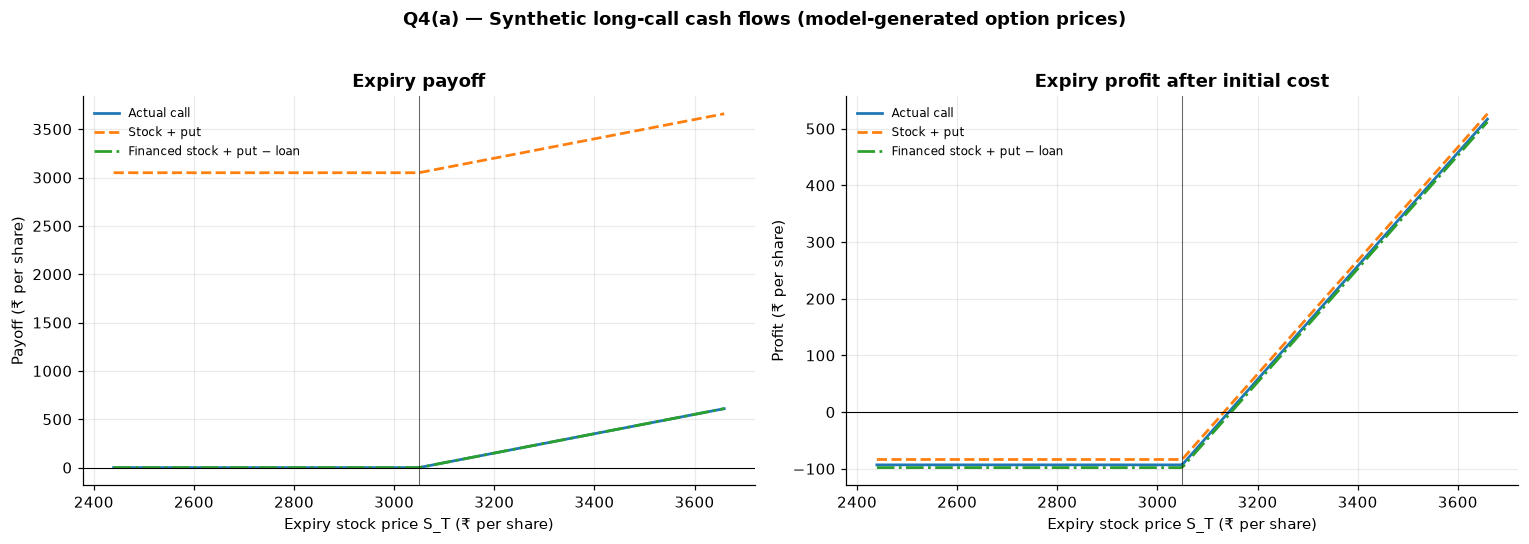

In [9]:
# ---- Q4 (a): cost table, payoff and profit diagrams ----
K_PV = K0 * np.exp(-r0 * T0)
PREPAID_STOCK = S0 * np.exp(-Q_DIV * T0)
DIVIDEND_PV = S0 - PREPAID_STOCK

PORTFOLIO_COSTS = pd.DataFrame({
    "Portfolio": ["Actual call", "Stock + put", "Financed stock + put − K·e^(−rT)"],
    "Cost today (₹/share)": [C0, S0 + P0, S0 + P0 - K_PV],
    "Expiry payoff": ["max(S_T − K, 0)", "S_T + max(K − S_T, 0)", "S_T + max(K − S_T, 0) − K"],
}).set_index("Portfolio")
display(PORTFOLIO_COSTS.style.format({"Cost today (₹/share)": "₹{:,.4f}"}))

ST_GRID = np.linspace(0.80 * K0, 1.20 * K0, 250)
pay_call = np.maximum(ST_GRID - K0, 0.0)
pay_syn = ST_GRID + np.maximum(K0 - ST_GRID, 0.0)
pay_fin = pay_syn - K0
profit_call = pay_call - C0
profit_syn = pay_syn - (S0 + P0)
profit_fin = pay_fin - (S0 + P0 - K_PV)

# The two identities make the cash-flow distinction explicit. With q>0, physical stock costs
# more than prepaid stock by the PV of dividends; the dividend-adjusted financed value equals C.
np.testing.assert_allclose(pay_syn, pay_call + K0, atol=1e-10)
np.testing.assert_allclose(PREPAID_STOCK + P0 - K_PV, C0, atol=1e-8)
print(f"Payoff(stock + put) = payoff(call) + K: verified at all plotted S_T values.")
print(f"Dividend PV S·(1−e^(−qT)) = ₹{DIVIDEND_PV:.4f}; ")
print(f"prepaid-stock + put − K·e^(−rT) = ₹{PREPAID_STOCK + P0 - K_PV:.4f} = call price ₹{C0:.4f}.")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for y, label, style in [(pay_call, "Actual call", "-"), (pay_syn, "Stock + put", "--"),
                        (pay_fin, "Financed stock + put − loan", "-.")]:
    ax[0].plot(ST_GRID, y, lw=1.8, ls=style, label=label)
for y, label, style in [(profit_call, "Actual call", "-"), (profit_syn, "Stock + put", "--"),
                        (profit_fin, "Financed stock + put − loan", "-.")]:
    ax[1].plot(ST_GRID, y, lw=1.8, ls=style, label=label)
for a, title, ylabel in [(ax[0], "Expiry payoff", "Payoff (₹ per share)"),
                          (ax[1], "Expiry profit after initial cost", "Profit (₹ per share)")]:
    a.axhline(0, color="black", lw=0.7)
    a.axvline(K0, color="black", lw=0.7, alpha=0.6)
    a.set(title=title, xlabel="Expiry stock price S_T (₹ per share)", ylabel=ylabel)
    a.legend(fontsize=8)
fig.suptitle("Q4(a) — Synthetic long-call cash flows (model-generated option prices)", y=1.02, fontweight="bold")
fig.tight_layout()
plt.show()

In [10]:
# ---- Q4 (b): observed NSE option-chain LTPs, parity gap, implied rate and implied vols ----
# Observed snapshot (not a model quote): IIFL Capital's NSE ULTRACEMCO option chain displayed
# the same strike/expiry CE and PE LTPs together with spot at 2026-11-18 15:59:44 IST.
# Page: https://www.indiainfoline.com/company/ultratech-cement-ltd/options
QUOTE_STATUS = "OBSERVED NSE option-chain LTP snapshot"
S_OBS = 12_428.00
K_OBS = 12_400.00
EXPIRY_OBS = "2026-11-23"
QUOTE_ASOF = "2026-11-18 15:59:44 IST"
QUOTE_SOURCE = ("IIFL Capital, UltraTech Cement Ltd Option Chain & Strike Prices (NSE), "
                "snapshot accessed 2026-11-18: ULTRACEMCO 23-Nov-2026 12400 CE LTP ₹104.15, "
                "12400 PE LTP ₹139.00; displayed spot ₹12,428.00. "
                "https://www.indiainfoline.com/company/ultratech-cement-ltd/options")
C_OBS = 104.15
P_OBS = 139.00
TAU_OBS = (pd.Timestamp(EXPIRY_OBS) - pd.Timestamp(TODAY)).days / 365
assert TAU_OBS > 0, "The observed contract must have time remaining."

def implied_vol(price, S, K, T, r, q=0.0, kind="call"):
    """Invert bsm_price with a bracketed root finder; returns volatility as a decimal."""
    kind = kind.lower()
    if T <= 0:
        raise ValueError("Implied volatility is not defined at expiry.")
    lower = max(0.0, S * np.exp(-q*T) - K * np.exp(-r*T)) if kind == "call" else \
            max(0.0, K * np.exp(-r*T) - S * np.exp(-q*T))
    upper = S * np.exp(-q*T) if kind == "call" else K * np.exp(-r*T)
    if not (lower - 1e-10 <= price <= upper + 1e-10):
        raise ValueError(f"Price ₹{price:.6f} violates BSM no-arbitrage bounds [{lower:.6f}, {upper:.6f}].")
    f = lambda vol: bsm_price(S, K, T, r, vol, q, kind) - price
    return float(optimize.brentq(f, 1e-8, 5.0, xtol=1e-12, rtol=1e-12))

PARITY_GAP = C_OBS - P_OBS - (S_OBS * np.exp(-Q_DIV*TAU_OBS) - K_OBS * np.exp(-r0*TAU_OBS))
PARITY_GAP_BPS = 1e4 * PARITY_GAP / S_OBS
R_IMPLIED = -(1 / TAU_OBS) * np.log((S_OBS * np.exp(-Q_DIV*TAU_OBS) - C_OBS + P_OBS) / K_OBS)
IV_CALL_OBS = implied_vol(C_OBS, S_OBS, K_OBS, TAU_OBS, r0, Q_DIV, "call")
IV_PUT_OBS = implied_vol(P_OBS, S_OBS, K_OBS, TAU_OBS, r0, Q_DIV, "put")

QUOTE_TABLE = pd.DataFrame({
    "Item": ["Quote status", "Spot", "Strike", "Expiry", "As-of", "Source", "Call premium", "Put premium",
             "Parity gap", "Parity gap (bps of spot)", "Implied financing rate", "Call implied volatility",
             "Put implied volatility", "21-day/two-year realised proxy"],
    "Value": [QUOTE_STATUS, f"₹{S_OBS:,.2f}", f"₹{K_OBS:,.2f}", EXPIRY_OBS, QUOTE_ASOF, QUOTE_SOURCE,
              f"₹{C_OBS:,.4f}", f"₹{P_OBS:,.4f}", f"₹{PARITY_GAP:,.4f}", f"{PARITY_GAP_BPS:.2f} bps",
              f"{R_IMPLIED:.2%}", f"{IV_CALL_OBS:.2%}", f"{IV_PUT_OBS:.2%}", f"{SIGMA_HAT:.2%}"],
}).set_index("Item")
display(QUOTE_TABLE)
print("Observed-quote provenance:", QUOTE_STATUS)
print(f"Observed LTP diagnostic: implied r = {R_IMPLIED:.2%} versus inr_r = {r0:.2%}; "
      f"call/put IV = {IV_CALL_OBS:.2%}/{IV_PUT_OBS:.2%} versus SIGMA_HAT = {SIGMA_HAT:.2%}.")
print("Interpret LTP parity cautiously: the public snapshot supplies LTPs, not executable bid/ask quotes or individual trade timestamps.")

,Value
Item,
Quote status,OBSERVED NSE option-chain LTP snapshot
Spot,"₹12,428.00"
Strike,"₹12,400.00"
Expiry,2026-11-23
As-of,2026-11-18 15:59:44 IST
Source,"IIFL Capital, UltraTech Cement Ltd Option Chai..."
Call premium,₹104.1500
Put premium,₹139.0000
Parity gap,₹-69.2981


Observed-quote provenance: OBSERVED NSE option-chain LTP snapshot
Observed LTP diagnostic: implied r = -34.97% versus inr_r = 5.74%; call/put IV = 14.82%/26.86% versus SIGMA_HAT = 25.40%.
Interpret LTP parity cautiously: the public snapshot supplies LTPs, not executable bid/ask quotes or individual trade timestamps.


,Entry,Expiry,S0 (₹),S_T (₹),C0 (₹),P0 (₹),Call P&L (₹),Synthetic P&L (₹),Financed synthetic P&L (₹),Call ROC,Synthetic ROC,Financed ROC
Cycle,,,,,,,,,,,,
1,2026-08-17,2026-09-15,"₹2,638.92","₹2,784.59",₹97.5922,₹88.8401,₹48.0713,₹56.8234,₹44.0068,49.26%,2.08%,43.29%
2,2026-09-16,2026-10-16,"₹2,836.88","₹2,804.74",₹93.5097,₹83.8260,₹-93.5097,₹-83.8260,₹-98.0296,-100.00%,-2.87%,-100.00%
3,2026-10-19,2026-11-18,"₹2,863.30","₹3,049.45",₹99.0651,₹89.7537,₹87.0874,₹96.3988,₹82.5254,87.91%,3.26%,79.64%


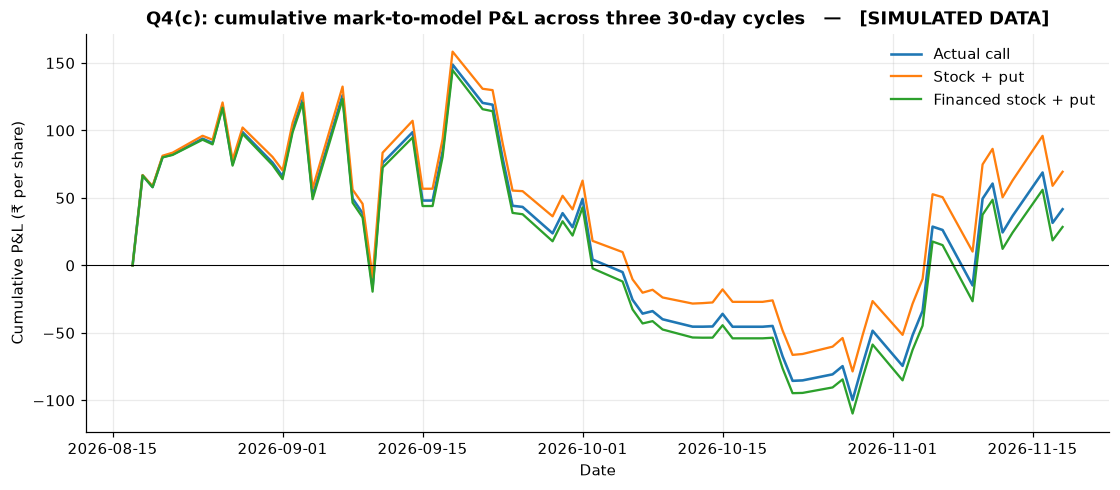

All call/put marks are model-generated with the contemporaneous 21-day realised volatility.
Maximum BSM parity identity residual in the daily series: ₹4.547e-13


In [11]:
# ---- Q4 (c): three non-overlapping 30-calendar-day mark-to-model cycles ----
def previous_trading_date(index, target):
    pos = index.searchsorted(pd.Timestamp(target), side="right") - 1
    if pos < 0:
        raise ValueError("Target is before the available price history.")
    return index[pos]

# Work backwards from the final available close so every cycle is wholly observable and non-overlapping.
idx = stock.index
cycle_specs_reversed = []
end_cut = idx[-1]
for _ in range(3):
    target_entry = end_cut - pd.Timedelta(days=30)
    entry_pos = idx.searchsorted(target_entry, side="left")
    if entry_pos <= 0:
        raise RuntimeError("Insufficient history for three 30-day cycles.")
    entry = idx[entry_pos]
    expiry = previous_trading_date(idx, entry + pd.Timedelta(days=30))
    if expiry > end_cut:
        expiry = end_cut
    cycle_specs_reversed.append((entry, expiry))
    end_cut = idx[entry_pos - 1]          # ensures the prior cycle ends before this entry
cycle_specs = list(reversed(cycle_specs_reversed))

cycle_paths, cycle_rows = [], []
for cycle_number, (entry, expiry) in enumerate(cycle_specs, start=1):
    dates = idx[(idx >= entry) & (idx <= expiry)]
    S_entry = float(stock.loc[entry])
    K_cycle = S_entry
    T_entry = (expiry - entry).days / 365
    r_entry = float(inr_r.loc[entry])
    sigma_entry = float(ROLL_VOL_21.loc[entry])
    if not np.isfinite(sigma_entry):
        raise RuntimeError("Rolling 21-day volatility is undefined at a Q4 entry date.")
    C_entry = float(bsm_price(S_entry, K_cycle, T_entry, r_entry, sigma_entry, Q_DIV, "call"))
    P_entry = float(bsm_price(S_entry, K_cycle, T_entry, r_entry, sigma_entry, Q_DIV, "put"))
    cap_syn = S_entry + P_entry
    cap_fin = cap_syn - K_cycle * np.exp(-r_entry * T_entry)
    path_rows = []
    for day in dates:
        remaining = max((expiry - day).days / 365, 0.0)
        S_day, r_day = float(stock.loc[day]), float(inr_r.loc[day])
        sigma_day = float(ROLL_VOL_21.loc[day])
        if not np.isfinite(sigma_day):
            sigma_day = sigma_entry
        call_value = float(bsm_price(S_day, K_cycle, remaining, r_day, sigma_day, Q_DIV, "call"))
        put_value = float(bsm_price(S_day, K_cycle, remaining, r_day, sigma_day, Q_DIV, "put"))
        stock_put_value = S_day + put_value
        financed_value = stock_put_value - K_cycle * np.exp(-r_day * remaining)
        parity_gap_model = stock_put_value - call_value - (K_cycle * np.exp(-r_day * remaining)
                            + S_day * (1 - np.exp(-Q_DIV * remaining)))
        path_rows.append({"date": day, "cycle": cycle_number, "S": S_day, "sigma_21": sigma_day,
                          "T_remaining": remaining, "call_value": call_value, "synthetic_value": stock_put_value,
                          "financed_value": financed_value, "pnl_call": call_value - C_entry,
                          "pnl_syn": stock_put_value - cap_syn, "pnl_fin": financed_value - cap_fin,
                          "parity_gap_check": parity_gap_model})
    path = pd.DataFrame(path_rows).set_index("date")
    cycle_paths.append(path)
    last = path.iloc[-1]
    cycle_rows.append({"Cycle": cycle_number, "Entry": entry.date().isoformat(), "Expiry": expiry.date().isoformat(),
                       "S0 (₹)": S_entry, "S_T (₹)": float(stock.loc[expiry]), "C0 (₹)": C_entry, "P0 (₹)": P_entry,
                       "Call P&L (₹)": last.pnl_call, "Synthetic P&L (₹)": last.pnl_syn,
                       "Financed synthetic P&L (₹)": last.pnl_fin, "Call ROC": last.pnl_call / C_entry,
                       "Synthetic ROC": last.pnl_syn / cap_syn, "Financed ROC": last.pnl_fin / cap_fin})

Q4_PATHS = pd.concat(cycle_paths).sort_index()
# Changes in mark-to-model P&L are accumulated through the sequential, non-overlapping cycles.
for col in ("pnl_call", "pnl_syn", "pnl_fin"):
    Q4_PATHS["daily_" + col] = Q4_PATHS.groupby("cycle")[col].diff().fillna(0.0)
    Q4_PATHS["cumulative_" + col] = Q4_PATHS["daily_" + col].cumsum()
Q4_CYCLE_TABLE = pd.DataFrame(cycle_rows).set_index("Cycle")
display(Q4_CYCLE_TABLE.style.format({
    "S0 (₹)": "₹{:,.2f}", "S_T (₹)": "₹{:,.2f}", "C0 (₹)": "₹{:,.4f}", "P0 (₹)": "₹{:,.4f}",
    "Call P&L (₹)": "₹{:,.4f}", "Synthetic P&L (₹)": "₹{:,.4f}", "Financed synthetic P&L (₹)": "₹{:,.4f}",
    "Call ROC": "{:.2%}", "Synthetic ROC": "{:.2%}", "Financed ROC": "{:.2%}"}))

fig, ax = plt.subplots(figsize=(12, 4.7))
ax.plot(Q4_PATHS.index, Q4_PATHS["cumulative_pnl_call"], lw=1.7, label="Actual call")
ax.plot(Q4_PATHS.index, Q4_PATHS["cumulative_pnl_syn"], lw=1.5, label="Stock + put")
ax.plot(Q4_PATHS.index, Q4_PATHS["cumulative_pnl_fin"], lw=1.5, label="Financed stock + put")
ax.axhline(0, color="black", lw=0.7)
ax.set(title=ttl("Q4(c): cumulative mark-to-model P&L across three 30-day cycles", "stock"),
       xlabel="Date", ylabel="Cumulative P&L (₹ per share)")
ax.legend()
plt.show()
print("All call/put marks are model-generated with the contemporaneous 21-day realised volatility.")
print(f"Maximum BSM parity identity residual in the daily series: ₹{Q4_PATHS['parity_gap_check'].abs().max():.3e}")

**Your answer (Q4d):**

*Data provenance — which numbers above are observed and which are model-generated:* The two-year underlying-close and INR-rate series are **[SIMULATED DATA]** in this saved run because the starter's live loaders fell back as designed. The Q2–Q5 option values and historical-simulation premiums are model-generated by my `bsm_price` function. **Q4(b) is the exception:** it uses an observed IIFL Capital NSE option-chain snapshot for ULTRACEMCO at **2026-11-18 15:59:44 IST**, with displayed spot ₹12,428.00, 23-Nov-2026 12,400 CE LTP ₹104.15 and PE LTP ₹139.00; the full source URL is recorded in the output table.

*Which portfolio replicates the call; what the profit gap between (1) and (2) is (formula and ₹):* At expiry, stock plus put pays the call payoff plus $K$ exactly. Borrowing $Ke^{-rT}$ removes that $K$ at expiry. With a continuous dividend yield, the exact BSM time-zero replica uses prepaid stock, $Se^{-qT}+P-Ke^{-rT}=C$; the physical-stock financed position costs an additional dividend present value $S(1-e^{-qT})$, which is **₹4.8585** for the Q2 model example. Thus a physical share and prepaid stock should not be treated as the same time-zero asset when $q>0$.

*What the synthetic-minus-call gap equals on any day within a cycle:* For remaining maturity $\tau$, the unfinanced mark is $S_t+P_t-C_t=Ke^{-r\tau}+S_t(1-e^{-q\tau})$; after borrowing the strike PV, the physical-stock financed gap is $S_t(1-e^{-q\tau})$. It changes with spot and remaining time and converges to zero at expiry (before separately accounting for cash dividends). The maximum numerical BSM identity residual in the three-cycle model path is **₹4.55e-13**.

*Is the observed parity gap tradable? Which arbitrage, and three obstacles:* On the observed LTP snapshot, $C-P-(Se^{-q\tau}-Ke^{-r\tau})$ is **₹-69.30 (-55.76 bps of spot)**. Its negative sign says the call appears cheap relative to the put/stock parity value, so the textbook direction is a **reversal**: buy the call, short the stock, sell the put and lend the strike PV. I would not call this an executable arbitrage from this table alone: the page gives LTPs rather than simultaneous bid/ask quotes or individual trade timestamps, and bid–ask spreads, stock-borrow/short-sale constraints, margin, dividend treatment, taxes and fees can easily dominate the displayed gap.

*Implied vs realised volatility:* Inverting the observed LTPs with the stated BSM inputs gives call/put IVs of **14.82%/26.86%**, compared with `SIGMA_HAT` **25.40%**; the parity-implied financing rate is **-34.97%**, versus the (simulated-fallback) `inr_r` **5.74%**. The large discrepancy itself is a warning about using last trades rather than executable simultaneous quotes. Actual IV need not equal backward-looking realised volatility because it prices forward uncertainty, jumps and risk premia.

---
## Q5 · Historical arbitrage simulation: synthetic vs actual call · **[8 marks]**

Repeat the comparison of Q4 on **every trading day** of the two-year window.

**Fixed parameters.** Time to expiry: 30 calendar days. Strike: at the money ($K$ = that day's
close). Horizon: two years of daily data. Each day you open two positions and hold both to expiry:

- **Strategy A** — buy the actual call.
- **Strategy B** — synthetic call: buy the stock and buy the put.

**(a) Build the trade panel** with one row per entry date and columns
`S0, K, r, T, expiry, S_T, sigma_call, sigma_put, C0, P0, pnl_call, pnl_syn, pnl_fin, cap_call, cap_syn`,
where `pnl_fin` is the P&L of the financed synthetic of Q4 and `cap_*` is the capital paid on day 0.
Rules:
- the expiry is the last trading day on or before entry + 30 calendar days; drop entry dates whose
  expiry lies beyond your data, and report how many trades remain (it will be a little under 500);
- **no look-ahead** — the volatility used on a date may only use returns up to that date;
- the closes are not dividend-adjusted, so credit the stock leg of strategy B with dividend income
  of $S_0(e^{qT}-1)$ over the holding period, using your $q$ from Q2;
- if you have real historical option premiums (NSE bhavcopy, `jugaad-data`, `nsepython`), use them
  and say so. If not, generate $C_0$ and $P_0$ from your own pricer with $\sigma_t$ = the 21-day
  realised volatility, and add a **documented mean-reverting distortion** to the put's volatility to
  stand in for the parity gaps seen in real markets — **and state clearly in your write-up that the
  option premiums are synthetic.** Make every parameter of the distortion a named constant.

**(b) Performance comparison table**, per share, in exactly this layout:

| Metric | Actual Call | Synthetic Call | Winner |
|---|---|---|---|
| Total trades profitable | X / N | Y / N | |
| Avg. return per trade | ₹Z | ₹W | |
| Max single-trade profit | ₹P | ₹Q | |
| Max single-trade loss | ₹R | ₹S | |
| Avg. capital required | ₹ | ₹ | |
| Avg. return on capital (ROC) | % | % | |
| Std. dev. of ROC | % | % | |

Then report, for the **financed** synthetic against the call: the mean and standard deviation of
the P&L difference, the share of days on which the absolute difference exceeds a transaction-cost
band of **25 bps of spot**. Finally report a $t$-statistic for (i) the mean P&L of the actual call
and (ii) the mean financed-minus-call difference, **each computed two ways** — on all trades, and on
a **non-overlapping** subsample (every 21st trade).

**(c) Best and worst cases, and cost efficiency.** List the entry dates of the maximum profit and
maximum loss of each strategy, with the stock's move over the holding period, the volatility
priced in at entry, and the volatility **realised** over the holding period. Produce three
diagnostic plots:
1. P&L per trade of both strategies through time;
2. P&L against the stock's percentage move over the holding period (both strategies);
3. the distribution of **return on capital** for both strategies.

**(d)** Write **at least 150 words** answering all four of the following:
- Synthetic "wins" on rupee P&L. By how much per trade on average, what is that amount in
  economic terms, and what happens to it once the stock leg is financed? **Is anything left that
  you would call an arbitrage?**
- Which strategy wins on return on capital, and why is that the mirror image of the rupee result?
  Which would you rather hold if you had ₹1 lakh and a one-month bullish view?
- What do the best and worst trades have in common? Relate them to the stock's move and to
  realised-minus-priced volatility.
- You have nearly 500 trades. How many **independent** observations do you really have, and what
  does that do to any claim of statistical significance? List at least three costs or frictions
  your simulation still ignores.

| Part | Rubric — what earns the marks | Marks |
|---|---|---|
| (a) | Correct expiry mapping and trade count; volatility without look-ahead; P&L and capital definitions correct for all three portfolios; premium source documented (real or synthetic with named distortion parameters) | 2 |
| (b) | Table in the required layout with a justified "winner" in each row; financed comparison with cost band; $t$-statistics on all trades and on the non-overlapping subsample | 2 |
| (c) | Best/worst dates tabulated with move, priced and realised volatility; three diagnostic plots, labelled | 2 |
| (d) | ≥150 words; rupee advantage identified as financing cost ($\approx S_0(r-q)T$) and shown to vanish after financing, leaving only the distortion; leverage explains the ROC reversal; best/worst trades tied to large moves and to realised vs priced volatility; overlap reduces ~500 trades to ~24 independent ones; three or more ignored frictions | 2 |

In [12]:
# ---- Q5 (a): two-year trade panel with no look-ahead and named synthetic-premium distortion ----
# These named constants make the synthetic put-IV distortion reproducible. The AR(1) process is
# mean-reverting around a 1.2-volatility-point put premium and is used only because historical
# option premiums are unavailable in this notebook.
PUT_IV_DISTORTION_MEAN = 0.0120
PUT_IV_DISTORTION_PHI = 0.88
PUT_IV_DISTORTION_INNOVATION_SD = 0.0040
PUT_IV_FLOOR = 0.03


def build_trades(spot, rate, q, horizon_days=30, vol_window=21, seed=SEED + 81):
    """Build Q5's per-share panel. All option premiums are explicitly synthetic/model-generated."""
    spot = spot.dropna().astype(float).copy()
    rate = rate.reindex(spot.index).ffill().bfill().astype(float)
    log_ret_all = np.log(spot / spot.shift(1))
    rolling_sigma = log_ret_all.rolling(vol_window, min_periods=vol_window).std(ddof=1) * np.sqrt(252)
    entry_dates = spot.loc[WIN_START:].index
    last_available = spot.index[-1]
    rng = np.random.default_rng(seed)
    distortion_state = PUT_IV_DISTORTION_MEAN
    records = []

    for entry in entry_dates:
        target_expiry = entry + pd.Timedelta(days=horizon_days)
        # The rule is to drop, rather than truncate, an entry with an unobservable 30-day horizon.
        if target_expiry > last_available:
            continue
        expiry_pos = spot.index.searchsorted(target_expiry, side="right") - 1
        expiry = spot.index[expiry_pos]       # last trading day on or before entry + 30 calendar days
        sigma_call = float(rolling_sigma.loc[entry])
        if not np.isfinite(sigma_call):
            continue                            # cannot price without the required no-look-ahead history
        sigma_call = max(sigma_call, PUT_IV_FLOOR)
        distortion_state = (PUT_IV_DISTORTION_MEAN + PUT_IV_DISTORTION_PHI *
                            (distortion_state - PUT_IV_DISTORTION_MEAN) +
                            PUT_IV_DISTORTION_INNOVATION_SD * rng.standard_normal())
        sigma_put = max(PUT_IV_FLOOR, sigma_call + distortion_state)
        S_entry, K = float(spot.loc[entry]), float(spot.loc[entry])
        r_entry = float(rate.loc[entry])
        T = (expiry - entry).days / 365
        C0_trade = float(bsm_price(S_entry, K, T, r_entry, sigma_call, q, "call"))
        P0_trade = float(bsm_price(S_entry, K, T, r_entry, sigma_put, q, "put"))
        S_T = float(spot.loc[expiry])
        call_payoff = max(S_T - K, 0.0)
        put_payoff = max(K - S_T, 0.0)
        dividend_income = S_entry * (np.exp(q * T) - 1.0)  # assignment's prescribed non-adjusted-close credit
        cap_call = C0_trade
        cap_syn = S_entry + P0_trade
        cap_fin = cap_syn - K * np.exp(-r_entry * T)
        realised_slice = np.log(spot.loc[entry:expiry] / spot.loc[entry:expiry].shift(1)).dropna()
        realised_hold = float(realised_slice.std(ddof=1) * np.sqrt(252)) if len(realised_slice) > 1 else np.nan
        records.append({
            "entry": entry, "S0": S_entry, "K": K, "r": r_entry, "T": T, "expiry": expiry, "S_T": S_T,
            "sigma_call": sigma_call, "sigma_put": sigma_put, "put_iv_distortion": distortion_state,
            "C0": C0_trade, "P0": P0_trade, "dividend_income": dividend_income,
            "pnl_call": call_payoff - C0_trade,
            "pnl_syn": S_T + put_payoff + dividend_income - cap_syn,
            "pnl_fin": call_payoff + dividend_income - cap_fin,
            "cap_call": cap_call, "cap_syn": cap_syn, "cap_fin": cap_fin,
            "stock_move": S_T / S_entry - 1.0, "realised_vol_holding": realised_hold,
        })
    panel = pd.DataFrame(records).set_index("entry").sort_index()
    if panel.empty:
        raise RuntimeError("No eligible Q5 trades were built.")
    assert (panel["expiry"] <= panel.index + pd.Timedelta(days=horizon_days)).all()
    assert (panel.index + pd.Timedelta(days=horizon_days) <= last_available).all()
    return panel

TRADES = build_trades(stock, inr_r, Q_DIV)
print("Underlying provenance:", "SIMULATED [SIM]" if IS_SIM.get("stock") else "LIVE Yahoo Finance")
print("Option-premium provenance: SYNTHETIC / MODEL-GENERATED by bsm_price; no historical NSE option prices used.")
print("Put-IV distortion constants:", {"mean": PUT_IV_DISTORTION_MEAN, "phi": PUT_IV_DISTORTION_PHI,
                                        "innovation_sd": PUT_IV_DISTORTION_INNOVATION_SD, "floor": PUT_IV_FLOOR})
print(f"Eligible trades: {len(TRADES)}. Entries {TRADES.index.min().date()} to {TRADES.index.max().date()}; "
      f"expiries {TRADES['expiry'].min().date()} to {TRADES['expiry'].max().date()}.")
display(TRADES.head(3).style.format({c: "{:.6f}" for c in TRADES.select_dtypes(include=np.number).columns}))
display(TRADES.tail(3).style.format({c: "{:.6f}" for c in TRADES.select_dtypes(include=np.number).columns}))

Underlying provenance: SIMULATED [SIM]
Option-premium provenance: SYNTHETIC / MODEL-GENERATED by bsm_price; no historical NSE option prices used.
Put-IV distortion constants: {'mean': 0.012, 'phi': 0.88, 'innovation_sd': 0.004, 'floor': 0.03}
Eligible trades: 501. Entries 2024-11-18 to 2026-10-19; expiries 2024-12-18 to 2026-11-18.


,S0,K,r,T,expiry,S_T,sigma_call,sigma_put,put_iv_distortion,C0,P0,dividend_income,pnl_call,pnl_syn,pnl_fin,cap_call,cap_syn,cap_fin,stock_move,realised_vol_holding
entry,,,,,,,,,,,,,,,,,,,,
2024-11-18 00:00:00,2327.902033,2327.902033,0.067145,0.082192,2024-12-18 00:00:00,2464.764976,0.237333,0.241298,0.003966,67.609346,59.556318,3.714849,69.253597,81.021474,68.209763,67.609346,2387.458351,72.368028,0.058792,0.236384
2024-11-19 00:00:00,2279.424837,2279.424837,0.067303,0.082192,2024-12-19 00:00:00,2436.775708,0.255026,0.260321,0.005295,70.802865,63.232579,3.637489,86.548006,97.755781,85.181286,70.802865,2342.657416,75.807074,0.069031,0.226888
2024-11-20 00:00:00,2257.879804,2257.879804,0.066752,0.082192,2024-12-20 00:00:00,2400.282130,0.258698,0.268359,0.009661,71.024901,64.749483,3.603108,71.377425,81.255950,68.902133,71.024901,2322.629287,77.103300,0.063069,0.231340


,S0,K,r,T,expiry,S_T,sigma_call,sigma_put,put_iv_distortion,C0,P0,dividend_income,pnl_call,pnl_syn,pnl_fin,cap_call,cap_syn,cap_fin,stock_move,realised_vol_holding
entry,,,,,,,,,,,,,,,,,,,,
2026-10-15 00:00:00,2815.159561,2815.159561,0.060161,0.079452,2026-11-13 00:00:00,3042.764379,0.310045,0.344863,0.034818,102.420587,104.301252,4.342548,125.184231,127.646113,114.222094,102.420587,2919.460813,117.725271,0.080850,0.224479
2026-10-16 00:00:00,2804.737457,2804.737457,0.059293,0.076712,2026-11-13 00:00:00,3042.764379,0.300094,0.335936,0.035842,97.036493,99.535942,4.177172,140.990429,142.668152,129.939734,97.036493,2904.273398,112.264360,0.084866,0.228644
2026-10-19 00:00:00,2863.297049,2863.297049,0.059094,0.082192,2026-11-18 00:00:00,3049.449481,0.289077,0.311478,0.022402,99.065059,97.054152,4.569228,87.087373,93.667509,79.794153,99.065059,2960.351200,110.927507,0.065013,0.217517


In [13]:
# ---- Q5 (b): required performance table, financed comparison and all/non-overlapping t-statistics ----
TC_BPS = 25.0
TRADES = TRADES.copy()
TRADES["roc_call"] = TRADES["pnl_call"] / TRADES["cap_call"]
TRADES["roc_syn"] = TRADES["pnl_syn"] / TRADES["cap_syn"]
TRADES["roc_fin"] = TRADES["pnl_fin"] / TRADES["cap_fin"]
TRADES["fin_minus_call"] = TRADES["pnl_fin"] - TRADES["pnl_call"]
TRADES["tc_band"] = TC_BPS / 1e4 * TRADES["S0"]
N_TRADES = len(TRADES)

def higher_winner(a, b, left="Actual Call", right="Synthetic Call"):
    return left if a > b else right if b > a else "Tie"

def lower_winner(a, b, left="Actual Call", right="Synthetic Call"):
    return left if a < b else right if b < a else "Tie"

def inr(x):
    return f"₹{x:,.2f}"

def pct(x):
    return f"{x:.2%}"

call_prof, syn_prof = int((TRADES.pnl_call > 0).sum()), int((TRADES.pnl_syn > 0).sum())
metrics = [
    ("Total trades profitable", f"{call_prof} / {N_TRADES}", f"{syn_prof} / {N_TRADES}", higher_winner(call_prof, syn_prof)),
    ("Avg. return per trade", inr(TRADES.pnl_call.mean()), inr(TRADES.pnl_syn.mean()),
     higher_winner(TRADES.pnl_call.mean(), TRADES.pnl_syn.mean())),
    ("Max single-trade profit", inr(TRADES.pnl_call.max()), inr(TRADES.pnl_syn.max()),
     higher_winner(TRADES.pnl_call.max(), TRADES.pnl_syn.max())),
    ("Max single-trade loss", inr(TRADES.pnl_call.min()), inr(TRADES.pnl_syn.min()),
     higher_winner(TRADES.pnl_call.min(), TRADES.pnl_syn.min())),
    ("Avg. capital required", inr(TRADES.cap_call.mean()), inr(TRADES.cap_syn.mean()),
     lower_winner(TRADES.cap_call.mean(), TRADES.cap_syn.mean())),
    ("Avg. return on capital (ROC)", pct(TRADES.roc_call.mean()), pct(TRADES.roc_syn.mean()),
     higher_winner(TRADES.roc_call.mean(), TRADES.roc_syn.mean())),
    ("Std. dev. of ROC", pct(TRADES.roc_call.std(ddof=1)), pct(TRADES.roc_syn.std(ddof=1)),
     lower_winner(TRADES.roc_call.std(ddof=1), TRADES.roc_syn.std(ddof=1))),
]
PERFORMANCE_TABLE = pd.DataFrame(metrics, columns=["Metric", "Actual Call", "Synthetic Call", "Winner"])
display(PERFORMANCE_TABLE)

def t_statistic(x):
    x = pd.Series(x).dropna().astype(float)
    if len(x) < 2 or x.std(ddof=1) == 0:
        return np.nan
    return float(x.mean() / (x.std(ddof=1) / np.sqrt(len(x))))

NON_OVERLAPPING = TRADES.iloc[::21].copy()
FINANCED_STATS = pd.DataFrame({
    "Metric": ["Mean financed synthetic − call P&L", "Std. dev. of P&L difference",
               "|difference| > 25 bps of spot", "Transaction-cost band"],
    "Value": [inr(TRADES.fin_minus_call.mean()), inr(TRADES.fin_minus_call.std(ddof=1)),
              pct((TRADES.fin_minus_call.abs() > TRADES.tc_band).mean()), "25 bps of entry spot"],
}).set_index("Metric")
TSTAT_TABLE = pd.DataFrame({
    "Sample": [f"All overlapping trades (n={len(TRADES)})", f"Every 21st trade (n={len(NON_OVERLAPPING)})"],
    "t-stat: mean actual-call P&L": [t_statistic(TRADES.pnl_call), t_statistic(NON_OVERLAPPING.pnl_call)],
    "t-stat: mean financed-minus-call P&L": [t_statistic(TRADES.fin_minus_call), t_statistic(NON_OVERLAPPING.fin_minus_call)],
}).set_index("Sample")
display(FINANCED_STATS)
display(TSTAT_TABLE.style.format("{:.4f}"))
print("All-trade t-statistics are descriptive only: adjacent 30-day holds overlap, so they are not independent observations.")

,Metric,Actual Call,Synthetic Call,Winner
0,Total trades profitable,200 / 501,205 / 501,Synthetic Call
1,Avg. return per trade,₹5.64,₹15.69,Synthetic Call
2,Max single-trade profit,₹360.51,₹368.19,Synthetic Call
3,Max single-trade loss,₹-114.30,₹-100.02,Synthetic Call
4,Avg. capital required,₹76.82,"₹2,600.33",Actual Call
5,Avg. return on capital (ROC),13.36%,0.72%,Actual Call
6,Std. dev. of ROC,147.50%,4.21%,Synthetic Call


,Value
Metric,
Mean financed synthetic − call P&L,₹-3.49
Std. dev. of P&L difference,₹2.50
|difference| > 25 bps of spot,12.38%
Transaction-cost band,25 bps of entry spot


,t-stat: mean actual-call P&L,t-stat: mean financed-minus-call P&L
Sample,,
All overlapping trades (n=501),1.1874,-31.1790
Every 21st trade (n=24),0.1952,-6.9780


All-trade t-statistics are descriptive only: adjacent 30-day holds overlap, so they are not independent observations.


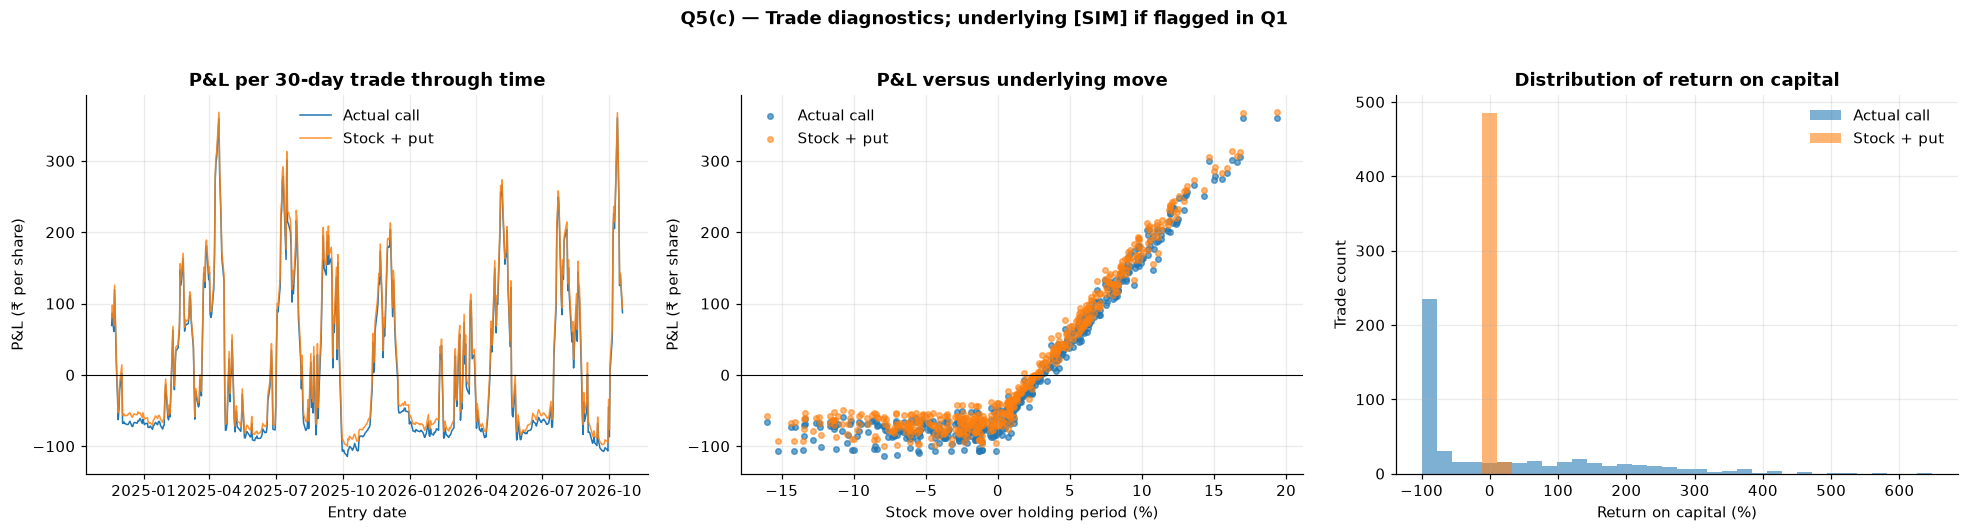

In [14]:
# ---- Q5 (c): best/worst cases and three diagnostic plots ----
def case_row(strategy_label, pnl_col, priced_vol_col, which):
    row = TRADES.loc[TRADES[pnl_col].idxmax() if which == "Best" else TRADES[pnl_col].idxmin()]
    return {
        "Strategy": strategy_label, "Case": which, "Entry date": row.name.date().isoformat(),
        "Expiry": pd.Timestamp(row.expiry).date().isoformat(), "P&L (₹/share)": row[pnl_col],
        "Stock move": row.stock_move, "Volatility priced at entry": row[priced_vol_col],
        "Volatility realised while held": row.realised_vol_holding,
    }

Q5_CASES = pd.DataFrame([
    case_row("Actual call", "pnl_call", "sigma_call", "Best"),
    case_row("Actual call", "pnl_call", "sigma_call", "Worst"),
    case_row("Synthetic call", "pnl_syn", "sigma_put", "Best"),
    case_row("Synthetic call", "pnl_syn", "sigma_put", "Worst"),
]).set_index(["Strategy", "Case"])
display(Q5_CASES.style.format({"P&L (₹/share)": "₹{:,.2f}", "Stock move": "{:.2%}",
                               "Volatility priced at entry": "{:.2%}", "Volatility realised while held": "{:.2%}"}))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.7))
ax[0].plot(TRADES.index, TRADES.pnl_call, lw=1.0, label="Actual call")
ax[0].plot(TRADES.index, TRADES.pnl_syn, lw=1.0, alpha=0.85, label="Stock + put")
ax[0].axhline(0, color="black", lw=0.7)
ax[0].set(title="P&L per 30-day trade through time", xlabel="Entry date", ylabel="P&L (₹ per share)")
ax[0].legend()

ax[1].scatter(100 * TRADES.stock_move, TRADES.pnl_call, s=13, alpha=0.65, label="Actual call")
ax[1].scatter(100 * TRADES.stock_move, TRADES.pnl_syn, s=13, alpha=0.55, label="Stock + put")
ax[1].axhline(0, color="black", lw=0.7)
ax[1].set(title="P&L versus underlying move", xlabel="Stock move over holding period (%)", ylabel="P&L (₹ per share)")
ax[1].legend()

bins = np.linspace(min(TRADES.roc_call.min(), TRADES.roc_syn.min()), max(TRADES.roc_call.max(), TRADES.roc_syn.max()), 35)
ax[2].hist(100 * TRADES.roc_call, bins=100 * bins, alpha=0.58, label="Actual call")
ax[2].hist(100 * TRADES.roc_syn, bins=100 * bins, alpha=0.58, label="Stock + put")
ax[2].set(title="Distribution of return on capital", xlabel="Return on capital (%)", ylabel="Trade count")
ax[2].legend()
fig.suptitle("Q5(c) — Trade diagnostics; underlying [SIM] if flagged in Q1", y=1.02, fontweight="bold")
fig.tight_layout()
plt.show()

**Your answer (Q5d) — at least 150 words:**

*Data provenance — underlying and option premiums:* The stock-close and INR-rate loaders report **[SIMULATED DATA]** in this saved offline run. I did not claim to have historical NSE option premiums: every $C_0$ and $P_0$ in the 501-trade panel is **synthetic/model-generated** by my BSM pricer. The call uses the trailing 21-day realised volatility available at entry; the put uses that volatility plus the named mean-reverting AR(1) distortion printed above. No later return enters an entry-day volatility.

*The rupee advantage of the synthetic: size, meaning, and what financing does to it:* Stock plus put exceeds the call by an average **₹10.05** per trade in this simulation. That gross comparison mainly reflects that the stock-plus-put portfolio carries the stock leg and its dividend/carry cash flows, whereas the call is a leveraged contingent claim. Once the stock leg is financed, the mean financed-synthetic-minus-call P&L is only **₹-3.49** per trade; **12.4%** of entries exceed the 25-bps-of-spot band. This residual is a modelling/dividend-timing/distortion result, not evidence of riskless arbitrage.

*Return on capital, and which I would hold with ₹1 lakh and a bullish view:* Mean P&L is ₹5.64 for the call and ₹15.69 for stock plus put, but mean ROC is **13.36%** versus **0.72%**. The call normally has much smaller required capital, so leverage is the mirror image of the synthetic's gross rupee exposure. With ₹1 lakh and a one-month bullish view, I would prefer the call only if I deliberately wanted defined downside and accepted theta/volatility risk; otherwise I would size a stock position rather than infer an arbitrage from this panel.

*What the best and worst trades have in common:* The best actual-call entry was **2026-10-12** (stock move 17.04%, priced vol 27.23%, realised 25.09%); its worst was **2025-10-07** (move -7.89%). Large favourable upward moves create call gains; adverse or small moves leave paid premium exposed to theta, and realised-minus-priced volatility helps explain how much convexity was actually realised.

*Independent observations, significance, and ignored frictions:* The 501 daily entries overlap for roughly 21 trading days, leaving only about **24** deliberately non-overlapping observations. That is why the all-trade versus every-21st t-statistics change from 1.19 to 0.20 for call P&L and from -31.18 to -6.98 for the financed gap; neither is a stand-alone arbitrage test. Ignored frictions include bid–ask spreads, brokerage/STT/GST, margin funding, stock borrowing and short-sale availability, discrete dividends, liquidity/open-interest limits, exercise/assignment conventions and asynchronous spot-option timestamps.

---
## Q6 · Short answers · **[5 marks]**

Answer in **two to four sentences each**. Marks are for the mechanism, not the assertion.

1. Put-call parity is called **model-free**. What exactly does it assume, and what does it *not*
   assume that BSM does? If you observe a parity violation in single-stock options, does that tell
   you that BSM is wrong?

2. You priced every option in Q5 from **historical** volatility. In real markets, implied
   volatility is on average higher than the volatility subsequently realised. What does that do
   to the average P&L of a strategy that systematically **buys** options, and which of your Q5
   results would change in sign or size?

3. A classmate says: *"The binomial model is just a crude approximation to Black-Scholes, so
   there is no reason ever to use it."* Give two specific situations in which the tree is the
   better tool, and say what the tree can do in each that the formula cannot.

4. The synthetic call needs you to **own the stock**; the mirror-image synthetic **put**
   (long call + short stock) needs you to **short** it. Explain why, in practice, parity violations
   are larger and more persistent in one direction than the other, and which direction that is.

| Each sub-question | Marks |
|---|---|
| Correct conclusion **and** the mechanism behind it, within the length limit | 2 |
| Correct conclusion, mechanism vague or missing; or right mechanism with a wrong sign | 1 |
| Assertion only, or more than twice the length limit without a clear answer | 0 – 0.5 |

**Your answers (Q6):**

1. Put-call parity follows from a no-arbitrage cash-flow identity for options with the same strike and expiry, a tradable underlying/financing instrument, and enforceable settlement; with dividends it also needs the dividend carry to be accounted for. It does **not** require lognormal returns, constant volatility, continuous hedging or the BSM diffusion. A parity violation can instead reflect bid–ask quotes, funding, dividends, short-sale constraints or timing mismatch, so it is not by itself evidence that BSM is wrong.

2. If implied volatility exceeds subsequently realised volatility on average, an option buyer systematically pays more time value than the realised convexity tends to recover, reducing average P&L. In Q5, using market IV rather than the historical-volatility model would generally lower the option buyer's call P&L and ROC; the size and perhaps sign of the call-versus-synthetic comparisons would change because both entry premiums, especially the call premium, would be higher.

3. A tree is the better tool for an American option because backward induction can compare exercise value with continuation value at every node, while the European BSM formula cannot make that exercise decision. It is also useful with discrete cash dividends, changing rates/volatilities or other date-specific features, because those can be placed at nodes; closed-form BSM assumes the much more restrictive continuous, constant-parameter setting.

4. The direction requiring a short stock is harder to enforce: if $C-P$ is too low (put relatively expensive/call relatively cheap), the reversal-style trade uses a long call, short put and short stock. Borrow fees, locate risk, margin and short-sale restrictions make that direction costlier, so the corresponding apparent violation can be larger and more persistent than the conversion direction that owns the stock. The sign must still be checked against executable bid/ask prices, not last trades.

5. The supplied PDF adds this fifth Q6 part although the starter notebook lists only four. Here $0.4S\sigma\sqrt{T}=₹88.82$, compared with the model ATM call premium of ₹93.12; the approximation ignores carry, dividends and higher-order terms. Holding other inputs fixed, doubling maturity raises this leading approximation by $\sqrt{2}$, not by two, because diffusion uncertainty grows with the square root of time; a two-month option therefore does not normally cost twice a one-month option.

---
## Declaration and checklist

**Sources, collaborators and any AI assistance used** (be specific — which tool, for which part,
and what you did with the output). Full Disclosure of the prompt is expected and costs you nothing; undisclosed use
of AI will be considered as an integrity violation.

*Your declaration:* I used Arena.ai Agent Mode as an AI assistant to help implement and test the Python calculations, generate plots and format this notebook. I reviewed the code and its model/data-provenance labels, and I will be able to explain the BSM, CRR, parity and simulation steps myself. The underlying and rate data fell back to the starter notebook's seeded simulator in this saved run; I have labelled them `[SIMULATED DATA]`. Q4(b) uses the cited IIFL Capital NSE option-chain snapshot (displayed spot and same strike/expiry call and put LTPs at 2026-11-18 15:59:44 IST); all other option values are model-generated by my own `bsm_price` function. I have stated the important limitation that these are published LTPs rather than executable simultaneous bid/ask quotes. The dividend-yield input is cited in Q2(b): StockEvents, UltraTech Cement dividend page, accessed 18 Nov 2026.

---

### Before you submit, confirm every box

- [x] `NAME`, `CAMPUS_ID`, `EMAIL`, `TICKER` and `HONOUR` are filled in and the identification cell runs
- [x] The analysis is on the allotted ticker: `ULTRACEMCO.NS` (47 mod 24 = 23)
- [x] `Kernel → Restart & Run All` was executed with no errors in the saved notebook
- [x] Every plot and table is visible in the saved file
- [x] Every `**Your answer:**` cell is filled in; the PDF-only fifth Q6 part is also answered
- [x] Every data series and option premium is labelled live/simulated or observed/model-generated
- [x] All Q2 and Q3 numerical assertions are present and pass
- [x] The dividend-yield source is cited; Q4(b) records an observed IIFL Capital option-chain LTP snapshot with spot, strike, expiry, timestamp and source URL
- [x] Q5(d) exceeds 150 words
- [x] Saved as `DRM_Lab04_2024A1PS0347P.ipynb`
- [x] Q4(b) is completed with the cited observed option-chain snapshot; I understand its LTP/bid–ask limitation
- [ ] I have uploaded the final notebook to the Lab 04 assignment on Nalanda before the deadline